<p align="center"><img src="assets/hero.svg" width="100%" alt="Gün 2 — Aktivasyon Fonksiyonları"></p>
<p align="center">
<img src="https://img.shields.io/badge/Gün-02-7C3AED?style=for-the-badge" alt="Gün 02">
<img src="https://img.shields.io/badge/Konu-Aktivasyon_Fonksiyonları-22D3EE?style=for-the-badge" alt="Aktivasyon fonksiyonları">
<img src="https://img.shields.io/badge/NumPy-013243?style=for-the-badge&amp;logo=numpy&amp;logoColor=white" alt="NumPy">
<img src="https://img.shields.io/badge/Matplotlib-11557C?style=for-the-badge" alt="Matplotlib">
<img src="https://img.shields.io/badge/Seviye-Sıfırdan-34D399?style=for-the-badge" alt="Sıfırdan">
</p>

<table><tr>
<td width="20%" align="center" valign="top"><h3>🎛️</h3><b>Sigmoid &amp; Tanh</b><br><br>Klasikler<br>0–1 ve −1…+1<br><br></td>
<td width="20%" align="center" valign="top"><h3>⚡</h3><b>ReLU Ailesi</b><br><br>ReLU · Leaky · PReLU<br>ölü nöron derdi<br><br></td>
<td width="20%" align="center" valign="top"><h3>🔮</h3><b>GELU</b><br><br>Yumuşak, olasılıksal<br>Transformer’ların seçimi<br><br></td>
<td width="20%" align="center" valign="top"><h3>🗳️</h3><b>Softmax</b><br><br>Çok sınıflı çıktı<br>skor → olasılık<br><br></td>
<td width="20%" align="center" valign="top"><h3>🏅</h3><b>Altın Kural</b><br><br>Gizli katman mı?<br>Çıktı katmanı mı?<br><br></td>
</tr></table>

<table><tr><td>

<img src="assets/etiket_hedef.svg" height="34" alt="hedef">

**Bu notebook sonunda şunları yapabileceksin:**

- **Aktivasyon fonksiyonunun** ne işe yaradığını ve Gün 1’deki ham skor `z`’nin neden tek başına yetmediğini anlatacaksın.
- **Sigmoid**’in ne yaptığını, **üç büyük sorununu** (kaybolan gradyan, 0 merkezli olmama, pahalı hesap) ve nerede hâlâ işe yaradığını göreceksin.
- **Tanh**’ın sigmoid’den farkını ve neden yine de derin ağlar için yetmediğini açıklayacaksın.
- **ReLU, Leaky ReLU, Parametric ReLU ve GELU**’yu, her birinin hangi sorunu çözdüğünü, **ölü nöron** (dead neuron) kavramıyla birlikte öğreneceksin.
- **Softmax**’ı elle hesaplayıp ham skorları olasılığa çevireceksin.
- Son olarak **Altın Kural**’ı ezberleyeceksin: *gizli katmanda hangisi, çıktı katmanında hangisi?* ve bunu **deneyle** kanıtlayacaksın.

**Ön koşul:** Gün 1 (perceptron, ağırlık, bias, türev fikri). Hatırlaman gereken tek cümle: *`z = w₁x₁ + w₂x₂ + b` ve aktivasyon bu `z`’yi karara çevirir.* Eksik kalan her terim geçtiği yerde yeniden açıklanıyor.

**YBS gözüyle:** Her bölümde kavramı bir işletme/öğrenci hayatı örneğine bağlıyoruz: spam filtresi, müşteri memnuniyeti, kredi onayı, destek talebi sınıflandırma, yangın kapısı, turnike, oylama.

</td></tr></table>

<p align="center"><img src="assets/yol_haritasi.svg" width="100%" alt="Gün 2 yol haritası: 11 durak"></p>

### 🧭 Hızlı Erişim

| Durak | Bölüm | Durak | Bölüm |
|:--:|:--|:--:|:--|
| 1 | [Neden Aktivasyon?](#b1) | 7 | [GELU](#b7) |
| 2 | [Sigmoid](#b2) | 8 | [Softmax](#b8) |
| 3 | [Sigmoid’in Üç Derdi](#b3) | 9 | [Altın Kural: Hangisi Nerede?](#b9) |
| 4 | [Tanh](#b4) | 10 | [Aktivasyon Arenası](#b10) |
| 5 | [ReLU](#b5) | 11 | [Kapanış: Özet, Sınav, Görevler](#b11) |
| 6 | [Leaky ReLU ve Parametric ReLU](#b6) | | |

<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="not">

Notebook’u `day02/` klasörü içinden çalıştırın; grafikler `outputs/figures/` klasörüne kaydedilir. Gün 1’deki gibi yalnızca **NumPy, Matplotlib ve pandas** kullanıyoruz; PyTorch ya da TensorFlow yok. Amaç yine aynı: sihirli kutuyu açıp **içinde ne olduğunu kendi elimizle hesaplamak**.

Kurulum gerekirse: `pip install numpy matplotlib pandas ipykernel`.

**Kaynak:** Bu notlar, Atıl SAMANCIOĞLU’nun **“Derin Öğrenme 2026: 100 Günlük Kamp”** Udemy kursundaki 5 ders dokümanından (Sigmoid, Tanh, ReLU–Leaky ReLU–PReLU–GELU, Softmax, Aktivasyon Fonksiyonları Cheat Sheet) alıntıdır; anlatım, analoji, animasyon ve ek deneyler bu notebook’a özgüdür. Kaynakta olmayan ek örnekler ayrıca **“ek örnek”** diye işaretlenmiştir.

</td></tr></table>

### 🧰 Kurulum: Kütüphaneler, Görsel Tema ve Fonksiyon Kutumuz

Gün 1’deki aynı koyu tema ve **aynı renk dili** geçerli: **mor = sigmoid/klasikler, camgöbeği = tanh/ileri akış, yeşil = ReLU ailesi/başarı, kehribar = uyarı/GELU, gül = hata/softmax.**

Bu hücrede bugünün **tüm aktivasyon fonksiyonlarını ve türevlerini** bir “alet çantası” olarak tanımlıyoruz. Her birini ilgili bölümde sökeceğiz.

In [1]:
from pathlib import Path
import math
import time

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.animation import FuncAnimation, PillowWriter

np.set_printoptions(precision=4, suppress=True)
pd.set_option('display.max_columns', 20)

FIG_DIR = Path('outputs/figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Tüm grafiklerde aynı anlam, aynı renk
RENK = {'mor': '#A78BFA', 'cam': '#22D3EE', 'amber': '#FBBF24', 'gul': '#FB7185', 'yesil': '#34D399',
        'metin': '#F8FAFC', 'soluk': '#94A3B8', 'zemin': '#0B1026', 'panel': '#111936', 'izgara': '#334155'}

mpl.rcParams.update({
    'figure.facecolor': RENK['zemin'], 'axes.facecolor': RENK['panel'], 'savefig.facecolor': RENK['zemin'],
    'axes.edgecolor': RENK['izgara'], 'axes.labelcolor': RENK['soluk'], 'xtick.color': RENK['soluk'],
    'ytick.color': RENK['soluk'], 'text.color': RENK['metin'], 'axes.titlecolor': RENK['metin'],
    'grid.color': RENK['izgara'], 'grid.alpha': 0.55, 'grid.linestyle': ':', 'axes.grid': True,
    'axes.axisbelow': True, 'axes.spines.top': False, 'axes.spines.right': False,
    'font.size': 11.5, 'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.labelsize': 11.5,
    'figure.dpi': 110, 'savefig.dpi': 160, 'savefig.bbox': 'tight', 'mathtext.fontset': 'dejavusans',
    'legend.facecolor': RENK['panel'], 'legend.edgecolor': RENK['izgara'], 'legend.labelcolor': RENK['metin'],
    'font.family': 'DejaVu Sans',
})


def baslik(fig, ana, alt=None, ust=0.80):
    """Grafiğe 'içgörü cümlesi' başlığı + açıklayıcı alt başlık ekler."""
    fig.subplots_adjust(top=ust)
    fig.text(0.012, 0.985, ana, fontsize=17, fontweight='bold', color=RENK['metin'], va='top', ha='left')
    if alt:
        fig.text(0.012, 0.985 - 0.095 * (5.0 / fig.get_figheight()), alt, fontsize=11.5, color=RENK['soluk'], va='top', ha='left')


def kaydet(fig, ad):
    fig.savefig(FIG_DIR / f'{ad}.png')
    plt.show()


# ───────── Bugünün alet çantası: aktivasyonlar ve türevleri ─────────
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

def sigmoid_turev(z):
    s = sigmoid(z)
    return s * (1.0 - s)                      # σ′ = σ(1 − σ)

def tanh(z):
    return np.tanh(z)

def tanh_turev(z):
    return 1.0 - np.tanh(z) ** 2              # tanh′ = 1 − tanh²

def relu(z):
    return np.maximum(0.0, z)                 # max(0, z)

def relu_turev(z):
    return (np.asarray(z) > 0).astype(float)  # z > 0 ise 1, değilse 0

def leaky_relu(z, a=0.01):
    return np.where(np.asarray(z) > 0, z, a * np.asarray(z))

def leaky_relu_turev(z, a=0.01):
    return np.where(np.asarray(z) > 0, 1.0, a)

KOK_2_PI = math.sqrt(2.0 / math.pi)

def gelu(x):
    """GELU'nun pratikte kullanılan tanh yaklaşığı (kaynaktaki formül)."""
    x = np.asarray(x, dtype=float)
    return 0.5 * x * (1.0 + np.tanh(KOK_2_PI * (x + 0.044715 * x ** 3)))

def gelu_turev(x):
    x = np.asarray(x, dtype=float)
    t = np.tanh(KOK_2_PI * (x + 0.044715 * x ** 3))
    return 0.5 * (1.0 + t) + 0.5 * x * (1.0 - t ** 2) * KOK_2_PI * (1.0 + 3 * 0.044715 * x ** 2)

def softmax(y):
    """Softmax (sayısal olarak güvenli sürüm: en büyük skoru çıkarıp hesaplar, sonucu değiştirmez)."""
    y = np.asarray(y, dtype=float)
    e = np.exp(y - np.max(y, axis=-1, keepdims=True))
    return e / np.sum(e, axis=-1, keepdims=True)


print('Hazır. NumPy', np.__version__, '· Matplotlib', mpl.__version__, '· pandas', pd.__version__)
print('Alet çantası: sigmoid, tanh, relu, leaky_relu, gelu, softmax (+ türevleri)')

Hazır. NumPy 2.3.3 · Matplotlib 3.10.6 · pandas 2.3.0
Alet çantası: sigmoid, tanh, relu, leaky_relu, gelu, softmax (+ türevleri)


<a id="b1"></a>

<p align="center"><img src="assets/bolum_01.svg" width="100%" alt="Bölüm 1 — Neden Aktivasyon?"></p>

### 🎭 Benzetme: Sınav Puanından Harf Notuna

Bir öğrencinin ham sınav puanı **87,4** ya da **−12** ya da **1500** olabilir; ama sistem sonunda **“geçti / kaldı”** ya da **“AA, BA, CB…”** demek zorunda. Ham puanı anlamlı bir **karara** çeviren bir **çeviri tablosuna** ihtiyaç var.

Sinir ağında da durum aynı. Gün 1’de gördük:

1. Girdiler **ağırlıklarla çarpılır**,
2. **Bias** eklenir,
3. Ortaya bir sayı çıkar: **`z`** (ham skor).

Ama bu `z` **tek başına yeterli değil.** Modelin karar verebilmesi için onu **anlamlı bir aralığa** dönüştürmemiz gerekir. İşte bu dönüşümü yapan şeye **aktivasyon fonksiyonu** diyoruz.

> 🧠 **Tek cümle:** Aktivasyon fonksiyonu, nöronun ham skorunu (`z`) **“ne kadar aktif olayım?”** cevabına çevirir.

<p align="center"><img src="assets/aktivasyon_ailesi.svg" width="100%" alt="Animasyon: aktivasyon ailesi, her fonksiyon bir öncekinin derdine çare"></p>

Yukarıdaki şema bugünün **hikâyesidir**: her fonksiyon, bir öncekinin **eksiğini** kapatmak için doğdu. Hikâyeyi bölüm bölüm yaşayacağız: Sigmoid → Tanh → ReLU → Leaky/PReLU → GELU. **Softmax** ise farklı bir görev için var: **çıktı katmanında çok sınıflı karar.**

### 📖 Mini Sözlük: Bugünün Yeni Kelimeleri

<table><tr>
<td width="25%" valign="top"><h4>🚦 Aktivasyon Fonksiyonu</h4><i>(activation function)</i><br><br>Nöronun ham skorunu <b>çıktıya</b> çeviren fonksiyon. Gün 1’de step ve sigmoid’i görmüştük.<br><br>🎭 <i>Ham puanı harf notuna çeviren tablo.</i></td>
<td width="25%" valign="top"><h4>🧱 Gizli Katman</h4><i>(hidden layer)</i><br><br>Girdi ile çıktı arasındaki katmanlar. Görevi <b>özellik öğrenmek</b>, karar vermek değil.<br><br>🎭 <i>Fabrikada ara istasyonlar.</i></td>
<td width="25%" valign="top"><h4>🎯 Çıktı Katmanı</h4><i>(output layer)</i><br><br>Son katman. Görevi <b>nihai kararı</b> üretmek ve yorumlanabilir hâle getirmek.<br><br>🎭 <i>Sevkiyat bölümü: koliyi müşteriye uygun paketler.</i></td>
<td width="25%" valign="top"><h4>🔢 Logit</h4><i>(ham sınıf skoru)</i><br><br>Çıktı katmanındaki <b>henüz olasılık olmayan</b> skor. Softmax’ın girdisi.<br><br>🎭 <i>Oylama öncesi ham puanlar.</i></td>
</tr><tr>
<td width="25%" valign="top"><h4>🪫 Doyma</h4><i>(saturation)</i><br><br>Girdi çok büyük ya da çok küçükken fonksiyonun <b>düzleşmesi</b>; eğim ≈ 0.<br><br>🎭 <i>Gaz pedalı sonuna kadar basılı: artık hız artmıyor.</i></td>
<td width="25%" valign="top"><h4>📉 Kaybolan Gradyan</h4><i>(vanishing gradient)</i><br><br>Geri yayılımda türevler çarpılırken <b>sinyalin sönmesi</b> (Gün 1’deki fısıltı oyunu).<br><br>🎭 <i>Fısıltı oyununda son kişiye ses ulaşmaz.</i></td>
<td width="25%" valign="top"><h4>⚖️ Zero-Centered</h4><i>(sıfır merkezli)</i><br><br>Çıktıların ortalamasının <b>yaklaşık 0</b> olması; yani hem artı hem eksi değer çıkması.<br><br>🎭 <i>Hem borç hem alacak yazabilen defter.</i></td>
<td width="25%" valign="top"><h4>💀 Ölü Nöron</h4><i>(dead neuron)</i><br><br>Sürekli 0 çıkaran, türevi de 0 olduğu için <b>bir daha güncellenemeyen</b> nöron.<br><br>🎭 <i>Şalteri bir kere kapanıp bir daha açılmayan makine.</i></td>
</tr></table>

### 🧪 Ham Skor Tek Başına Ne Kadar Anlamsız? (Gün 1 Öğrencileriyle)

Gün 1’deki ağırlıkları hatırla: `w₁ = 0.04` (IQ), `w₂ = 0.6` (çalışma saati), `b = −5`. Üç öğrencimize ve takip öğrencimize ek olarak, **çok çalışkan bir “Süper” öğrenci** (IQ 130, günde 10 saat) ekleyelim ve hepsinin ham skorunu hesaplayalım:

In [2]:
isimler = ['A', 'B', 'C', 'Takip', 'Süper']
X1 = np.array([[95, 3], [110, 4], [100, 5], [100, 4], [130, 10]], dtype=float)   # [IQ, günlük çalışma saati]
w1 = np.array([0.04, 0.6]); b1 = -5.0

z1 = X1 @ w1 + b1
p1 = sigmoid(z1)

tablo1 = pd.DataFrame({'IQ': X1[:, 0].astype(int), 'Çalışma (saat)': X1[:, 1].astype(int),
                       'z (ham skor)': z1, 'σ(z)': p1,
                       'Yorum': [f'%{v * 100:.0f} geçme ihtimali' for v in p1]}, index=isimler)
display(tablo1.round(3))

,IQ,Çalışma (saat),z (ham skor),σ(z),Yorum
A,95,3,0.6,0.646,%65 geçme ihtimali
B,110,4,1.8,0.858,%86 geçme ihtimali
C,100,5,2.0,0.881,%88 geçme ihtimali
Takip,100,4,1.4,0.802,%80 geçme ihtimali
Süper,130,10,6.2,0.998,%100 geçme ihtimali


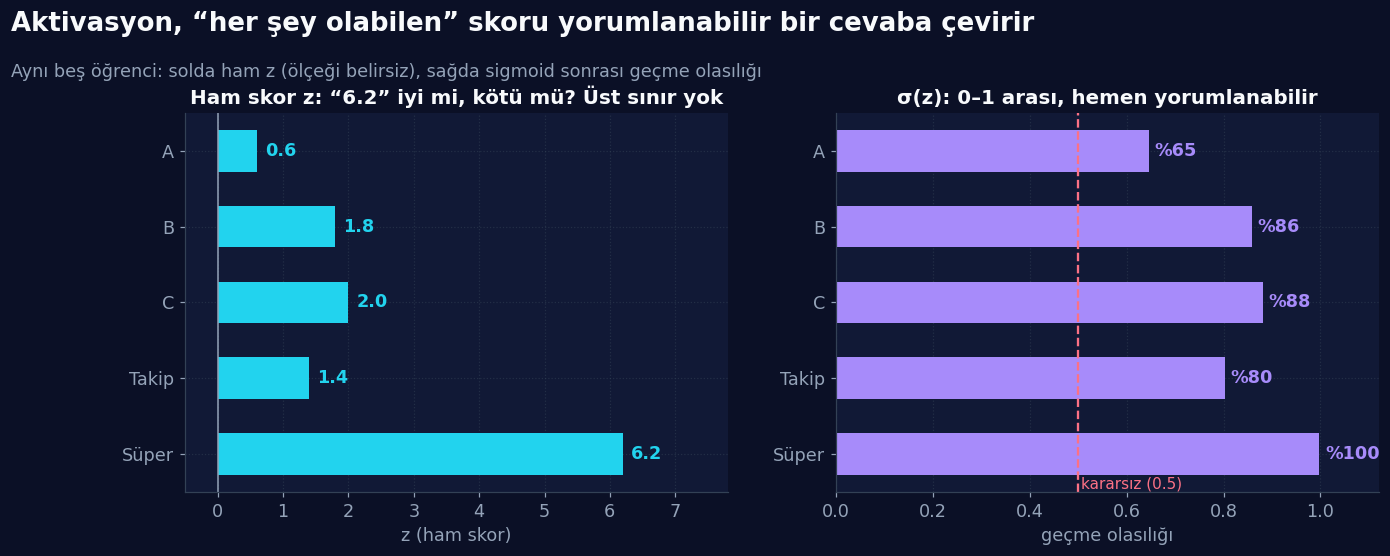

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.0))

# Sol: ham skor: ölçeği belli değil
ax1.barh(isimler, z1, color=RENK['cam'], height=0.55)
for i, v in enumerate(z1):
    ax1.text(v + 0.12, i, f'{v:.1f}', va='center', color=RENK['cam'], fontsize=11.5, fontweight='bold')
ax1.axvline(0, color=RENK['soluk'], lw=1)
ax1.set_xlim(-0.5, 7.8); ax1.invert_yaxis()
ax1.set_title('Ham skor z: “6.2” iyi mi, kötü mü? Üst sınır yok'); ax1.set_xlabel('z (ham skor)')

# Sağ: sigmoid sonrası: 0–1 arası, olasılık gibi
ax2.barh(isimler, p1, color=RENK['mor'], height=0.55)
for i, v in enumerate(p1):
    ax2.text(v + 0.012, i, f'%{v * 100:.0f}', va='center', color=RENK['mor'], fontsize=11.5, fontweight='bold')
ax2.axvline(0.5, color=RENK['gul'], lw=1.5, ls='--'); ax2.text(0.505, 4.45, 'kararsız (0.5)', color=RENK['gul'], fontsize=10)
ax2.set_xlim(0, 1.12); ax2.invert_yaxis()
ax2.set_title('σ(z): 0–1 arası, hemen yorumlanabilir'); ax2.set_xlabel('geçme olasılığı')

baslik(fig, 'Aktivasyon, “her şey olabilen” skoru yorumlanabilir bir cevaba çevirir',
       'Aynı beş öğrenci: solda ham z (ölçeği belirsiz), sağda sigmoid sonrası geçme olasılığı', ust=0.80)
kaydet(fig, '01_z_ve_sigmoid')

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="icgoru">

**İki iş birden yapıyor:**

1. **Aralığı sınırlıyor:** `z = 0.6` da olur, `z = 6.2` de olur; sigmoid bunların hepsini **0 ile 1 arasına** sığdırıyor.
2. **Doğrusal olmayanlık katıyor:** Gün 1’de gördük: aktivasyon olmadan 10 katman da koysan **tek bir doğrusal katmandan farksızsın.** Aktivasyon, ağa *karmaşık şekilleri öğrenme gücünü* veren şeydir.

Bu iki iş için **birçok farklı fonksiyon** geliştirildi. Hepsini tanıyalım, çünkü **yanlış seçim, doğru modeli bile bozar.**

</td></tr></table>

<a id="b2"></a>

<p align="center"><img src="assets/bolum_02.svg" width="100%" alt="Bölüm 2 — Sigmoid"></p>

### 🎭 Benzetme: Dimmer (Işık Kısıcı) ve Yüzdelik Çevirici

Evdeki **dimmer** düğmesini sonsuza kadar çevirsen de ışık %100’ü geçmez, ters yöne sonsuza kadar çevirsen de %0’ın altına inmez. **Sigmoid** böyle bir dimmer’dir: içine **ne kadar büyük ya da küçük bir `z` atarsan at**, çıktı **hep 0 ile 1 arasında** kalır.

Matematiksel olarak:

> **σ(z) = 1 / (1 + e⁻ᶻ)**

Burada `z` = ağırlıklı toplam + bias, `σ(z)` = aktivasyon sonrası çıktıdır. (`e` ≈ 2.718, matematikteki özel bir sabittir; `e⁻ᶻ` büyük `z` için çok küçülür, küçük `z` için çok büyür. İşin sırrı bu.)

**Sigmoid’in en önemli özelliği:** *Girdi ne olursa olsun, çıktı her zaman 0 ile 1 arasındadır.* Animasyonda kaydırıcıyı izle:

<p align="center"><img src="assets/sigmoid_anim.svg" width="100%" alt="Animasyon: z kaydırıcısı hareket ederken sigmoid çıktısı 0 ile 1 arasında kalır"></p>

### 🔬 Sayılarla Sigmoid

Sihir yok, sadece `1 / (1 + e⁻ᶻ)`. Birkaç `z` için elle (ya da kodla) hesaplayalım:

In [4]:
z_degerleri = np.array([-6, -4, -2, -1, 0, 1, 2, 4, 6], dtype=float)
sig_tablosu = pd.DataFrame({'z': z_degerleri.astype(int), 'e⁻ᶻ': np.exp(-z_degerleri), 'σ(z) = 1/(1+e⁻ᶻ)': sigmoid(z_degerleri)})
sig_tablosu['Yorum'] = np.where(z_degerleri < -2, 'neredeyse kapalı', np.where(z_degerleri > 2, 'neredeyse tam açık', np.where(z_degerleri == 0, 'tam ortada (kararsız)', 'kısmen açık')))
display(sig_tablosu.set_index('z').round(4))

print('σ(0) =', sigmoid(0.0), '→ tam ortada, kararsız')
print('Simetri: σ(−z) = 1 − σ(z) her z için doğru mu?', np.allclose(sigmoid(-z_degerleri), 1 - sigmoid(z_degerleri)))

,e⁻ᶻ,σ(z) = 1/(1+e⁻ᶻ),Yorum
z,,,
-6,403.4288,0.0025,neredeyse kapalı
-4,54.5982,0.0180,neredeyse kapalı
-2,7.3891,0.1192,kısmen açık
-1,2.7183,0.2689,kısmen açık
0,1.0000,0.5000,tam ortada (kararsız)
1,0.3679,0.7311,kısmen açık
2,0.1353,0.8808,kısmen açık
4,0.0183,0.9820,neredeyse tam açık
6,0.0025,0.9975,neredeyse tam açık


σ(0) = 0.5 → tam ortada, kararsız
Simetri: σ(−z) = 1 − σ(z) her z için doğru mu? True


Grafikte **“S” harfine benzeyen** bir eğri görüyoruz (adı da buradan: *sigmoid = S şeklinde*). Kaynak dokümandaki yorumla:

- `z` **çok negatifse** çıktı **0’a** yaklaşır,
- `z` **çok pozitifse** çıktı **1’e** yaklaşır,
- `z = 0` iken çıktı tam **0.5**’tir. Bu yüzden sigmoid bazen şöyle yorumlanır: **“Bir nöronun ne kadar aktif olduğunu gösterir.”**

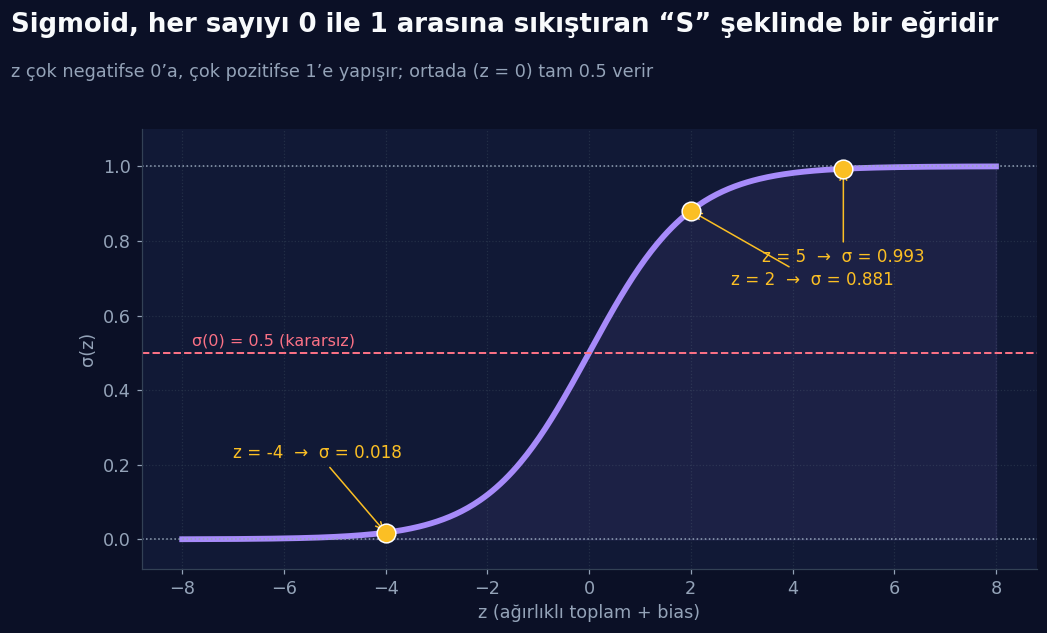

In [5]:
z_ekseni = np.linspace(-8, 8, 400)
fig, ax = plt.subplots(figsize=(10.5, 5.8))
ax.plot(z_ekseni, sigmoid(z_ekseni), color=RENK['mor'], lw=3.8)
ax.fill_between(z_ekseni, 0, sigmoid(z_ekseni), color=RENK['mor'], alpha=0.08)
ax.axhline(1, color=RENK['soluk'], lw=1, ls=':'); ax.axhline(0, color=RENK['soluk'], lw=1, ls=':')
ax.axhline(0.5, color=RENK['gul'], lw=1.3, ls='--'); ax.text(-7.8, 0.52, 'σ(0) = 0.5 (kararsız)', color=RENK['gul'], fontsize=10.5)
for zn, dx, dy in [(-4, -3.0, 0.2), (2, 0.8, -0.2), (5, -1.6, -0.25)]:
    ax.scatter([zn], [sigmoid(zn)], s=150, color=RENK['amber'], edgecolor='white', zorder=5)
    ax.annotate(f'z = {zn}  →  σ = {sigmoid(zn):.3f}', (zn, sigmoid(zn)), xytext=(zn + dx, sigmoid(zn) + dy), color=RENK['amber'], fontsize=11,
                arrowprops=dict(arrowstyle='->', color=RENK['amber']))
ax.set_xlabel('z (ağırlıklı toplam + bias)'); ax.set_ylabel('σ(z)'); ax.set_ylim(-0.08, 1.1)
baslik(fig, 'Sigmoid, her sayıyı 0 ile 1 arasına sıkıştıran “S” şeklinde bir eğridir',
       'z çok negatifse 0’a, çok pozitifse 1’e yapışır; ortada (z = 0) tam 0.5 verir', ust=0.80)
kaydet(fig, '02_sigmoid_egrisi')

### 🧪 “Sıkıştırma” Gerçekten Oluyor mu? 10.000 Rastgele Skor

Rastgele (simülasyon) 10.000 ham skor üretelim: bazıları çok büyük, bazıları çok küçük olsun (`ortalama 0`, `standart sapma 4`). Sigmoid’den geçince ne olacak?

Ham skor aralığı   :  -14.64  …   16.25
Sigmoid sonrası    :  0.0000  …  1.0000


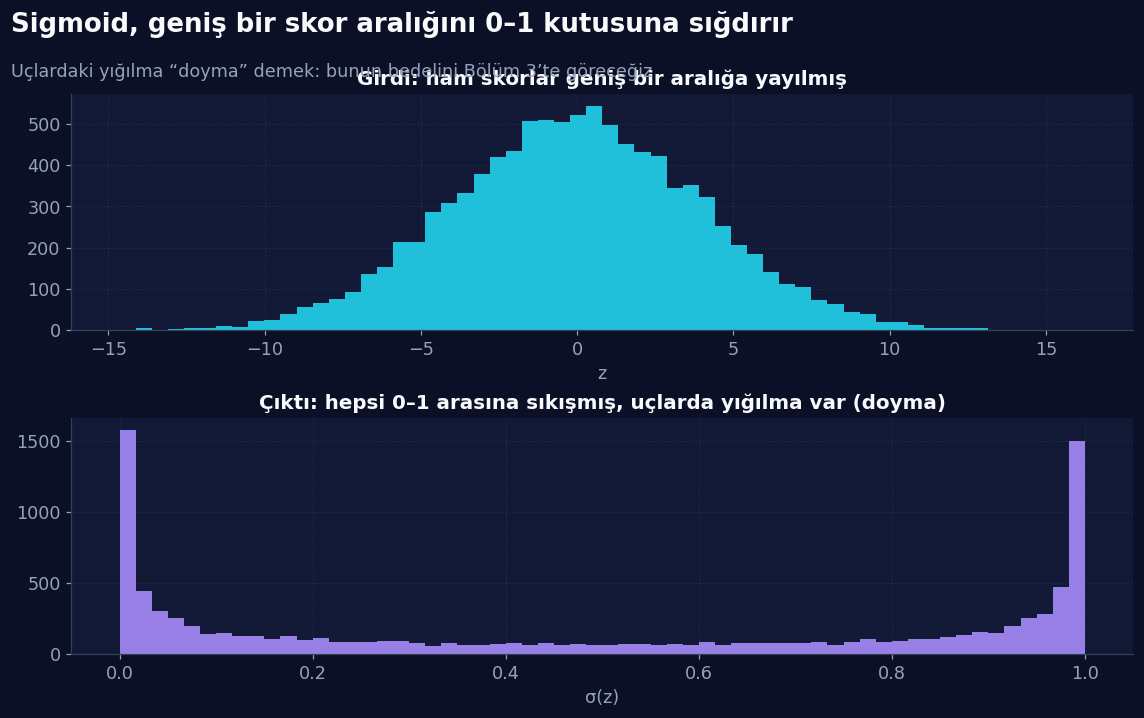

In [6]:
rng = np.random.default_rng(7)
z_rastgele = rng.normal(0, 4, 10_000)
s_rastgele = sigmoid(z_rastgele)
print(f'Ham skor aralığı   : {z_rastgele.min():7.2f}  …  {z_rastgele.max():6.2f}')
print(f'Sigmoid sonrası    : {s_rastgele.min():7.4f}  …  {s_rastgele.max():6.4f}')

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10.5, 6.6), sharex=False)
ax1.hist(z_rastgele, bins=60, color=RENK['cam'], alpha=0.9)
ax1.set_title('Girdi: ham skorlar geniş bir aralığa yayılmış'); ax1.set_xlabel('z')
ax2.hist(s_rastgele, bins=60, color=RENK['mor'], alpha=0.9)
ax2.set_title('Çıktı: hepsi 0–1 arasına sıkışmış, uçlarda yığılma var (doyma)'); ax2.set_xlabel('σ(z)')
fig.tight_layout()
baslik(fig, 'Sigmoid, geniş bir skor aralığını 0–1 kutusuna sığdırır', 'Uçlardaki yığılma “doyma” demek: bunun bedelini Bölüm 3’te göreceğiz', ust=0.87)
kaydet(fig, '02_sigmoid_ezme')

<table><tr><td>

<img src="assets/etiket_ybs.svg" height="34" alt="ybs">

**YBS örneği, spam filtresi:** Bir e-postanın ham “spam skoru” `z = 2.2` çıktı diyelim. Sigmoid’den geçirince `σ(2.2) ≈ 0.90`, yani **“%90 ihtimalle spam”**. Eşik `0.5` ise `0.90 > 0.5` olduğu için e-posta **spam kutusuna** gider. Sigmoid’in kullanım alanı tam olarak budur: **ikili (binary) sorulara “evet olasılığı” üretmek.** (spam/değil, hasta/sağlıklı, onay/ret.)

</td></tr></table>

In [7]:
z_spam = 2.2
p_spam = sigmoid(z_spam)
print(f'z = {z_spam}  →  σ(z) = {p_spam:.3f}  →  %{p_spam * 100:.0f} ihtimalle spam')
print('Karar (eşik 0.5):', 'SPAM kutusuna' if p_spam > 0.5 else 'gelen kutusuna')

z = 2.2  →  σ(z) = 0.900  →  %90 ihtimalle spam
Karar (eşik 0.5): SPAM kutusuna


### ✅ Sigmoid Ne İşe Yaradı?

Kaynak dokümana göre sigmoid uzun yıllar boyunca popülerdi, çünkü:

- Çıktıyı **0–1 aralığına sıkıştırır**,
- **Binary (ikili) problemler** için uygundur,
- **Basit ve sezgiseldir.**

Bu yüzden **lojistik regresyon** ve **küçük sinir ağları** gibi yapılarda yaygın kullanıldı. Peki madem bu kadar güzel, **neden artık derin ağların içinde kullanmıyoruz?** Cevap bir sonraki bölümde: **üç büyük derdi var.**

<a id="b3"></a>

<p align="center"><img src="assets/bolum_03.svg" width="100%" alt="Bölüm 3 — Sigmoid'in Üç Derdi"></p>

### 🎭 Benzetme: Üç Başlı Dert

Sigmoid’in **üç temel problemi** var (kaynak dokümandaki sıralamayla):

<table><tr>
<td width="33%" valign="top"><h4>1️⃣ Kaybolan Gradyan</h4>Türevi <b>en fazla 0.25</b>. Derin ağda çarpıla çarpıla sinyal söner.<br><br>🎭 <i>Fısıltı oyunu.</i></td>
<td width="33%" valign="top"><h4>2️⃣ Sıfır Merkezli Değil</h4>Çıktı hep <b>(0, 1)</b> arası, yani hep pozitif. Ortalama ≈ 0.5.<br><br>🎭 <i>Sadece “artı” yazabilen defter.</i></td>
<td width="33%" valign="top"><h4>3️⃣ Üstel (exp) İşlem</h4>İçinde <code>e⁻ᶻ</code> var: hesaplaması <b>pahalı</b>.<br><br>🎭 <i>Basit toplama yerine her seferinde ağır bir hesap makinesi.</i></td>
</tr></table>

Sırayla üçünü de **deneyle** görelim.

### 1️⃣ Türev: Sigmoid’in Eğimi

Gün 1’den hatırla: **geri yayılımda (backpropagation)** en kritik şey, aktivasyon fonksiyonunun **türevidir** (eğimidir). Eğim ne kadar büyükse ağırlıklar o kadar rahat güncellenir. Sigmoid’in türevi şu güzel formüle sahip:

> **σ′(z) = σ(z) · (1 − σ(z))**

Bu formül önemli bir sonuç doğurur: **σ′(z) hiçbir zaman 0.25’ten büyük olamaz.** (Çünkü `a·(1−a)` çarpımı `a = 0.5`’te en büyüktür: `0.5 × 0.5 = 0.25`.) Kaynaktaki ifadeyle: `0 < σ′(z) ≤ 0.25`.

σ′(z) en büyük değeri: 0.2500   (z = 0.01 noktasında)
  z = 0:  σ′ = 0.25000
  z = 2:  σ′ = 0.10499
  z = 4:  σ′ = 0.01766
  z = 6:  σ′ = 0.00247
  z = 8:  σ′ = 0.00034


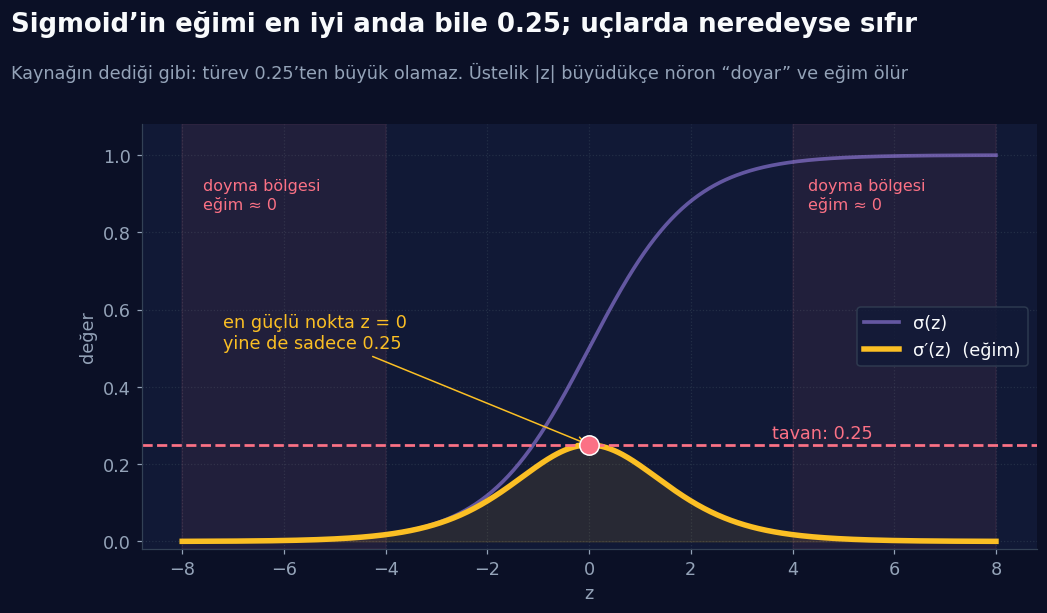

In [8]:
z_ekseni = np.linspace(-8, 8, 600)
turev = sigmoid_turev(z_ekseni)
print(f'σ′(z) en büyük değeri: {turev.max():.4f}   (z = {z_ekseni[turev.argmax()]:.2f} noktasında)')
for zn in [0, 2, 4, 6, 8]:
    print(f'  z = {zn}:  σ′ = {sigmoid_turev(float(zn)):.5f}')

fig, ax = plt.subplots(figsize=(10.5, 5.6))
ax.plot(z_ekseni, sigmoid(z_ekseni), color=RENK['mor'], lw=2.4, alpha=0.55, label='σ(z)')
ax.plot(z_ekseni, turev, color=RENK['amber'], lw=3.6, label='σ′(z)  (eğim)')
ax.fill_between(z_ekseni, 0, turev, color=RENK['amber'], alpha=0.10)
ax.axhline(0.25, color=RENK['gul'], ls='--', lw=1.8); ax.text(3.6, 0.268, 'tavan: 0.25', color=RENK['gul'], fontsize=11.5)
ax.axvspan(-8, -4, color=RENK['gul'], alpha=0.07); ax.axvspan(4, 8, color=RENK['gul'], alpha=0.07)
ax.text(-7.6, 0.86, 'doyma bölgesi\neğim ≈ 0', color=RENK['gul'], fontsize=10.5); ax.text(4.3, 0.86, 'doyma bölgesi\neğim ≈ 0', color=RENK['gul'], fontsize=10.5)
ax.scatter([0], [0.25], s=160, color=RENK['gul'], edgecolor='white', zorder=5)
ax.annotate('en güçlü nokta z = 0\nyine de sadece 0.25', (0, 0.25), xytext=(-7.2, 0.5), color=RENK['amber'], fontsize=11.5, arrowprops=dict(arrowstyle='->', color=RENK['amber']))
ax.set_xlabel('z'); ax.set_ylabel('değer'); ax.set_ylim(-0.02, 1.08); ax.legend(loc='center right')
baslik(fig, 'Sigmoid’in eğimi en iyi anda bile 0.25; uçlarda neredeyse sıfır',
       'Kaynağın dediği gibi: türev 0.25’ten büyük olamaz. Üstelik |z| büyüdükçe nöron “doyar” ve eğim ölür', ust=0.80)
kaydet(fig, '03_sigmoid_turevi')

Şimdi bunu **zincir kuralıyla** birleştirelim (Gün 1’de gördük): geri yayılımda türevler **art arda çarpılır**. Her katmanda sigmoid türevi devreye girdiği için:

> `0.25 × 0.25 × 0.25 × …`

Bu çarpım **çok hızlı** sıfıra yaklaşır. En iyi durumda bile (her çarpan tam 0.25):

In [9]:
n = np.array([1, 2, 3, 4, 6, 8, 10])
carpim = pd.DataFrame({'Katman sayısı (n)': n, 'Çarpım 0.25ⁿ': [f'{0.25 ** k:.2e}' for k in n],
                       'Geriye kalan sinyal': [f'1 / {4 ** k:,}'.replace(',', '.') for k in n]}).set_index('Katman sayısı (n)')
display(carpim)

,Çarpım 0.25ⁿ,Geriye kalan sinyal
Katman sayısı (n),,
1,2.50e-01,1 / 4
2,6.25e-02,1 / 16
3,1.56e-02,1 / 64
4,3.91e-03,1 / 256
6,2.44e-04,1 / 4.096
8,1.53e-05,1 / 65.536
10,9.54e-07,1 / 1.048.576


<p align="center"><img src="assets/fisilti_oyunu.svg" width="100%" alt="Animasyon (Gün 1'den): fısıltı oyunu, her katmanda ses çeyreğe düşer"></p>

Gün 1’deki **fısıltı oyununu** hatırla: her oyuncu mesajı **en fazla dörtte birine** kısıyor. Sonuç, kaynak dokümandaki ifadeyle:

- **Derin katmanlardaki ağırlıklar neredeyse hiç güncellenmez,**
- **Öğrenme çok yavaşlar ya da tamamen durur.**

Bu sorunun adı: **Vanishing Gradient Problemi.**

### 2️⃣ Sigmoid Neden “Zero-Centered” Değil?

Sigmoid’in çıktı aralığı **(0, 1)**; yani çıktı **asla negatif olmaz**, ortalaması da genellikle **≈ 0.5** olur. Kaynak, bunun pratikte iki sonuç doğurduğunu söylüyor:

- Gradient descent **daha verimsiz** çalışır,
- Ağırlık güncellemeleri **dengesiz** olur.

Makine öğrenmesinde **ortalaması sıfır** olan değerlerle çalışmak genellikle daha etkilidir. Önce “ortalama” iddiasını ölçelim:

In [10]:
rng = np.random.default_rng(0)
z_orn = rng.normal(0, 2, 100_000)         # simülasyon: ortalaması 0 olan ham skorlar
print(f'Girdi z ortalaması          : {z_orn.mean():+.4f}')
print(f'sigmoid(z) çıktı ortalaması : {sigmoid(z_orn).mean():+.4f}   ← 0 değil, 0.5 civarı')
print(f'tanh(z)    çıktı ortalaması : {np.tanh(z_orn).mean():+.4f}   ← 0 civarı (zero-centered)')

Girdi z ortalaması          : -0.0018
sigmoid(z) çıktı ortalaması : +0.4999   ← 0 değil, 0.5 civarı
tanh(z)    çıktı ortalaması : -0.0002   ← 0 civarı (zero-centered)


**Peki bu neden önemli?** Sezgiyle anlatalım. Bir nöronun ağırlığını güncellerken ihtiyaç duyduğumuz gradyan şu yapıdadır:

> **∂L/∂wᵢ = δ · aᵢ**  (`δ`: bu nörona gelen hata sinyali, `aᵢ`: o ağırlığın bağlı olduğu **önceki katman çıktısı**)

Eğer `aᵢ`’ler **hep pozitifse** (sigmoid çıktıları gibi), bütün `wᵢ` gradyanları `δ`’nın **aynı işaretini** taşır. Yani ağırlıkların **hepsi birden artar ya da hepsi birden azalır**; “birini artır, diğerini azalt” diyemezsin.

> 🎭 **Benzetme:** Bir halatı 4 kişi çekiyor ama kurallar gereği **hepsi aynı anda ya çekmek ya bırakmak zorunda.** Hedef sağ-çapraz bir yerdeyse, doğrudan gidemezsin; **zikzak çizersin.** Zikzak = zaman kaybı.

Önce işareti görelim: 4 girdili bir nöron, `δ = −0.7`:

In [11]:
rng = np.random.default_rng(3)
onceki_z = rng.normal(0, 1.5, 4)          # önceki katmanın 4 nöronunun ham skoru (simülasyon)
delta = -0.7                              # bu nörona gelen hata sinyali (örnek değer)

tablo_isaret = pd.DataFrame({
    'Önceki çıktı (sigmoid)': sigmoid(onceki_z), 'Gradyan δ·a (sigmoid)': delta * sigmoid(onceki_z),
    'Önceki çıktı (tanh)': np.tanh(onceki_z),   'Gradyan δ·a (tanh)': delta * np.tanh(onceki_z),
}, index=['w₁', 'w₂', 'w₃', 'w₄'])
display(tablo_isaret.round(3))
print('Sigmoid girdileri → gradyan işaretleri :', np.sign(delta * sigmoid(onceki_z)).astype(int), ' (hepsi aynı!)')
print('Tanh girdileri    → gradyan işaretleri :', np.sign(delta * np.tanh(onceki_z)).astype(int), ' (karışık: her ağırlık kendi yönüne gidebilir)')

,Önceki çıktı (sigmoid),Gradyan δ·a (sigmoid),Önceki çıktı (tanh),Gradyan δ·a (tanh)
w₁,0.955,-0.669,0.996,-0.697
w₂,0.021,-0.015,-0.999,0.699
w₃,0.652,-0.456,0.556,-0.389
w₄,0.299,-0.209,-0.692,0.484


Sigmoid girdileri → gradyan işaretleri : [-1 -1 -1 -1]  (hepsi aynı!)
Tanh girdileri    → gradyan işaretleri : [-1  1 -1  1]  (karışık: her ağırlık kendi yönüne gidebilir)


### 🧪 Ek Örnek (kaynakta yok): Zikzak Deneyi

Bu etkiyi **gerçekten ölçelim.** Basit bir model: iki girdili **tek bir doğrusal nöron** (`ŷ = w₁a₁ + w₂a₂`). Hedef ağırlıklar `(w₁, w₂) = (1, −1)`, başlangıç `(−1, 0)`. Yani `w₁` **artmalı**, `w₂` **azalmalı.** İki durumu karşılaştırıyoruz:

- **Pozitif girdiler** (ortalama 0.5, sigmoid çıktıları gibi),
- **Sıfır merkezli girdiler** (ortalama 0, tanh çıktıları gibi).

İkisinin de girdi dağılımı aynı genişlikte (`std = 0.15`); **tek fark ortalama.** Adil olmak için her durumda **en iyi öğrenme oranını** tarıyoruz (hedefe en az adımda varan `η`) ve **o** öğrenme oranıyla ilk adımların yolunu çiziyoruz:

In [12]:
def zikzak_kos(ortalama, eta_kati, adim=60, tohum=1):
    r = np.random.default_rng(tohum)
    A = r.normal(ortalama, 0.15, size=(500, 2))           # girdiler (önceki katman çıktısı gibi)
    w_hedef = np.array([1.0, -1.0]); y_ = A @ w_hedef
    H = 2 * A.T @ A / len(A)                               # kaybın eğriliği (Hessian)
    eta = eta_kati / np.linalg.eigvalsh(H).max()
    w = np.array([-1.0, 0.0]); yol = [w.copy()]; kayip_ = []
    for _ in range(adim):
        g = 2 * A.T @ (A @ w - y_) / len(A)
        w = w - eta * g; yol.append(w.copy()); kayip_.append(((A @ w - y_) ** 2).mean())
    return np.array(yol), np.array(kayip_), A, y_

def kac_adimda(L, esik=1e-3):
    return int(np.argmax(L < esik)) + 1 if (L < esik).any() else None

def en_iyi_kos(ortalama):
    """0.1 … 1.95 / λmax arasındaki öğrenme oranlarını dener, hedefe en az adımda varanı seçer."""
    en_iyi = None
    for kat in np.linspace(0.1, 1.95, 38):
        yol, L, A, y_ = zikzak_kos(ortalama, kat)
        k = kac_adimda(L)
        if k and (en_iyi is None or k < en_iyi[0]):
            en_iyi = (k, kat, yol, L, A, y_)
    return en_iyi

adim_poz, kat_poz, yol_poz, L_poz, A_poz, y_poz = en_iyi_kos(0.5)
adim_sifir, kat_sifir, yol_sifir, L_sifir, A_sifir, y_sifir = en_iyi_kos(0.0)

def yon_tersleme(yol, n=40):
    d = np.diff(yol[:n], axis=0)
    return int(((d[1:] * d[:-1]).sum(axis=1) < 0).sum())     # ardışık adımların yönü ters mi?

print(f'Pozitif girdiler (ort. 0.5)     : en iyi η = {kat_poz:.2f}/λmax  →  kayıp < 0.001 için {adim_poz} adım,  ilk 40 adımda {yon_tersleme(yol_poz)} kez yön tersleme (zikzak)')
print(f'Sıfır merkezli girdiler (ort. 0): en iyi η = {kat_sifir:.2f}/λmax  →  kayıp < 0.001 için {adim_sifir} adım,  ilk 40 adımda {yon_tersleme(yol_sifir)} kez yön tersleme')
assert adim_poz > 5 * adim_sifir and yon_tersleme(yol_poz) > 10 and yon_tersleme(yol_sifir) == 0

Pozitif girdiler (ort. 0.5)     : en iyi η = 1.85/λmax  →  kayıp < 0.001 için 27 adım,  ilk 40 adımda 26 kez yön tersleme (zikzak)
Sıfır merkezli girdiler (ort. 0): en iyi η = 0.95/λmax  →  kayıp < 0.001 için 1 adım,  ilk 40 adımda 0 kez yön tersleme


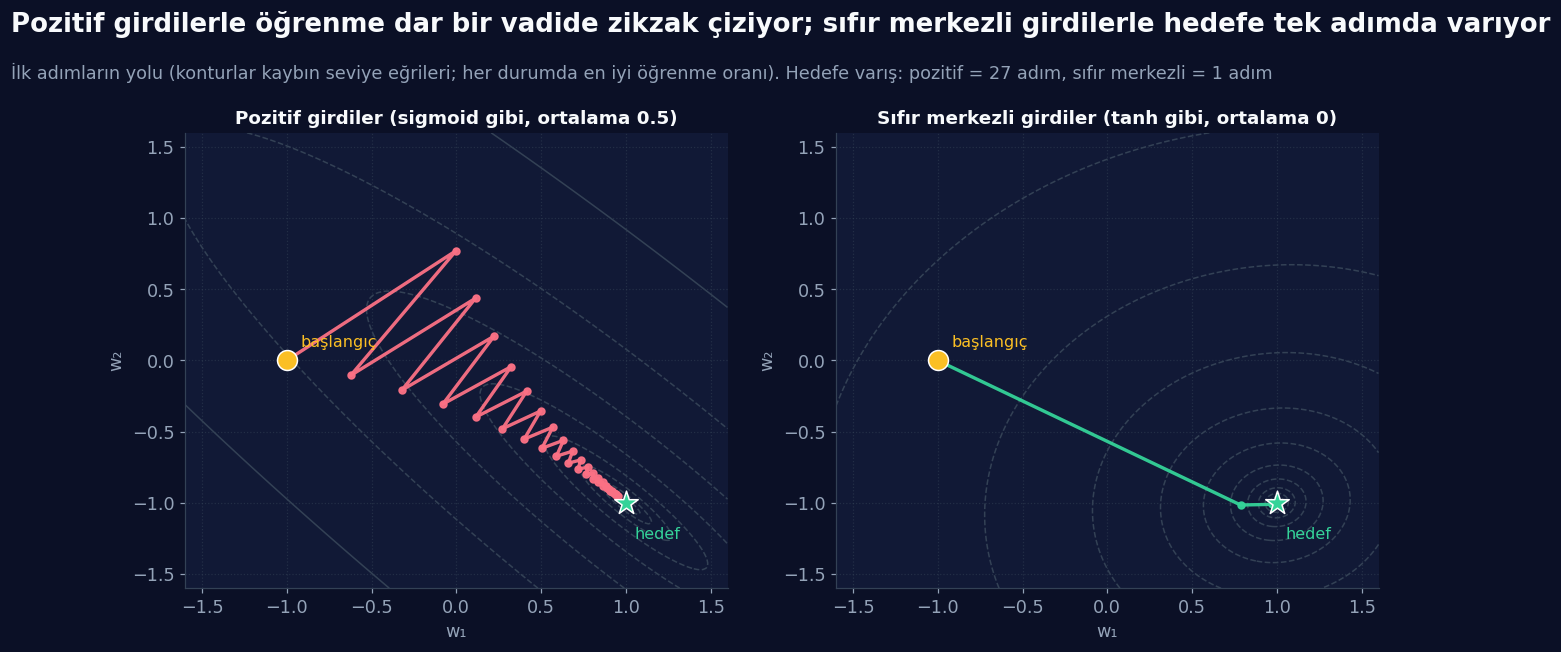

In [13]:
fig, eksenler = plt.subplots(1, 2, figsize=(14, 6.0))
w1g, w2g = np.meshgrid(np.linspace(-1.6, 1.6, 200), np.linspace(-1.6, 1.6, 200))
for ax, yol, A_, y_, renk, ad in [(eksenler[0], yol_poz, A_poz, y_poz, RENK['gul'], 'Pozitif girdiler (sigmoid gibi, ortalama 0.5)'),
                                  (eksenler[1], yol_sifir, A_sifir, y_sifir, RENK['yesil'], 'Sıfır merkezli girdiler (tanh gibi, ortalama 0)')]:
    P = np.stack([w1g.ravel(), w2g.ravel()], axis=1)
    Lyuzey = ((A_ @ P.T - y_[:, None]) ** 2).mean(axis=0).reshape(w1g.shape)
    ax.contour(w1g, w2g, np.log10(Lyuzey + 1e-9), levels=14, colors=RENK['izgara'], linewidths=1)
    ax.plot(yol[:40, 0], yol[:40, 1], '-o', color=renk, lw=2.2, ms=4.5, alpha=0.95)
    ax.scatter(*yol[0], s=170, color=RENK['amber'], edgecolor='white', zorder=6); ax.text(yol[0, 0] + 0.08, yol[0, 1] + 0.1, 'başlangıç', color=RENK['amber'], fontsize=10.5)
    ax.scatter(1, -1, s=260, marker='*', color=RENK['yesil'], edgecolor='white', zorder=6); ax.text(1.05, -1.25, 'hedef', color=RENK['yesil'], fontsize=10.5)
    ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.6, 1.6); ax.set_xlabel('w₁'); ax.set_ylabel('w₂'); ax.set_title(ad, fontsize=12)
baslik(fig, 'Pozitif girdilerle öğrenme dar bir vadide zikzak çiziyor; sıfır merkezli girdilerle hedefe tek adımda varıyor',
       f'İlk adımların yolu (konturlar kaybın seviye eğrileri; her durumda en iyi öğrenme oranı). Hedefe varış: pozitif = {adim_poz} adım, sıfır merkezli = {adim_sifir} adım', ust=0.80)
kaydet(fig, '03_zikzak')

<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="dikkat">

**Dürüst bir not:** Bu deney, **tek bir doğrusal nöron** üzerinde etkiyi izole eden bir oyuncak modeldir; gerçek bir ağın içinde etki başka faktörlerle karışır. Ama sezgi aynıdır ve kaynağın söylediğiyle örtüşür: **girdiler hep pozitifse** gradyan descent **daha verimsiz** çalışır. Sıfır merkezli bir aktivasyon (tanh) bu yükü hafifletir. Bunu Bölüm 4’te kullanacağız.

</td></tr></table>

### 3️⃣ Üstel (exp) İşlem: Pahalı Hesap

Sigmoid’in içinde `e⁻ᶻ` var; yani **üstel (exponential) işlem** gerekiyor. Üstel hesap, basit bir karşılaştırmaya (`max(0, z)`, ReLU) göre **daha yavaştır.** Küçük bir ağda fark hissedilmez ama milyarlarca hesapta toplanır. Bu hızı **ölçerek** Bölüm 10’da (Aktivasyon Arenası) göreceğiz; şimdilik bu üçüncü derdi not alalım.

### ⚖️ Sigmoid’in Terazisi

<table><tr>
<td width="50%" valign="top"><h4>✅ Avantajları</h4><ul><li>Basit ve sezgisel</li><li>Çıktıyı 0–1 aralığına sıkıştırır</li><li>Binary (ikili) sınıflandırmaya uygun</li></ul></td>
<td width="50%" valign="top"><h4>⚠️ Dezavantajları</h4><ul><li>Vanishing gradient problemi</li><li>Zero-centered olmaması</li><li>Üstel (exponential) işlem içermesi</li></ul></td>
</tr></table>

<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="sonuc">

**Sonuç (kaynakla birebir):** Sigmoid **tarihsel olarak çok önemlidir**, **binary problemler için uygundur**, ama **derin ağlarda ciddi problemlere yol açar.** Bu yüzden sigmoid, **derin ağların gizli katmanları için iyi bir tercih değildir.**

Hâlâ **çıktı katmanında** ve **binary classification** problemlerinde sıkça kullanılır. Bu problemleri aşmak için sıradaki fonksiyona geçiyoruz: **tanh.**

</td></tr></table>

<a id="b4"></a>

<p align="center"><img src="assets/bolum_04.svg" width="100%" alt="Bölüm 4 — Tanh"></p>

### 🎭 Benzetme: İbresi Ortada Duran Terazi

Sigmoid’in sorunlarını sayalım: çıktıyı 0–1’e sıkıştırır, türevi en fazla 0.25, derin ağlarda kaybolan gradyan yaratır ve **sıfır merkezli değildir.** Doğal soru şu:

> *“Sigmoid’e benzeyen ama bu sorunları biraz daha iyi yöneten bir fonksiyon var mı?”*

Kaynağın bu soruya verdiği ilk cevap: **tanh (hyperbolic tangent, hiperbolik tanjant).**

Tanh’ı **ibresi ortada duran bir terazi** gibi düşün: sol kefe ağır basarsa ibre **−1**’e, sağ kefe ağır basarsa **+1**’e gider, denge varsa **0**’da durur. Sigmoid ise ibresi hep sağda başlayan (0’dan başlayıp 1’e giden) bir terazidir.

> **tanh(z) = (eᶻ − e⁻ᶻ) / (eᶻ + e⁻ᶻ)**

`z` yine aynı: **ağırlıklı toplam + bias.** Tanh’ın en önemli özelliği: **çıktısı −1 ile +1 arasındadır.**

🎭 **YBS örneği:** Müşteri yorumlarının duygu skorunu düşün: **−1 = çok olumsuz, 0 = nötr, +1 = çok olumlu.** Negatif duyguyu da ifade edebilen tanh bu iş için doğal bir dildir; sigmoid ise “olumlu olma olasılığı”nı (0–1) söyler.

<p align="center"><img src="assets/sigmoid_tanh_anim.svg" width="100%" alt="Animasyon: aynı z değeri için sigmoid ve tanh çıktıları"></p>

### 🔬 Sayılarla Tanh ve Sigmoid’le Akrabalığı

In [14]:
zt = np.array([-3, -2, -1, 0, 1, 2, 3], dtype=float)
display(pd.DataFrame({'z': zt.astype(int), 'tanh(z)': tanh(zt), 'σ(z)': sigmoid(zt)}).set_index('z').round(4))

# Ek örnek (kaynakta yok): tanh aslında "ölçeklenmiş ve kaydırılmış" bir sigmoid'dir
z_ts = np.linspace(-6, 6, 1001)
print('tanh(z) = 2·σ(2z) − 1  her z için doğru mu?', np.allclose(tanh(z_ts), 2 * sigmoid(2 * z_ts) - 1))
print('tanh(0) =', tanh(0.0), ' → orijinden geçer')

,tanh(z),σ(z)
z,,
-3,-0.9951,0.0474
-2,-0.9640,0.1192
-1,-0.7616,0.2689
0,0.0000,0.5000
1,0.7616,0.7311
2,0.9640,0.8808
3,0.9951,0.9526


tanh(z) = 2·σ(2z) − 1  her z için doğru mu? True
tanh(0) = 0.0  → orijinden geçer


Tabloda şu **üç şey** görünüyor (kaynaktaki yorumla):

- `z` **çok pozitifse** çıktı **+1**’e, **çok negatifse −1**’e yaklaşır,
- Fonksiyon **orijinden geçer** (`tanh(0) = 0`),
- Sigmoid gibi **lineer olmayanlık** katar ve nöronun ne kadar aktif olduğunu gösterir. **Fark:** tanh **zero-centered**’dır.

Ek örnek olarak (kaynakta yok) bir de şunu doğruladık: `tanh(z) = 2σ(2z) − 1`. Yani tanh, sigmoid’in **iki kat gerilmiş ve aşağı kaydırılmış** hâlidir. İkisi aynı ailenin üyesi.

### ⚖️ Zero-Centered Olmak Neden Önemli?

Kaynağa göre “zero-centered” demek: **çıktıların ortalaması yaklaşık 0’dır.** Bunun sağladığı şeyler:

- Gradient descent **daha dengeli** çalışır,
- Ağırlık güncellemeleri **daha verimli** olur.

Bu yüzden tanh, sigmoid’e göre **pratikte daha hızlı ve daha stabil öğrenir.** Bölüm 3’teki **zikzak deneyinin** (sıfır merkezli girdiler hedefe doğrudan gidiyordu) tam olarak anlattığı şey budur.

### 📐 Tanh’ın Türevi

> **d/dz tanh(z) = 1 − tanh²(z)**

Kaynağın söylediği: tanh’ın türevi **0 ile 1 arasındadır.** Sigmoid’in türevi **en fazla 0.25**’ti; tanh’ınki **en fazla 1.** Yani aynı koşulda tanh **dört kat daha güçlü gradyan** taşıyabilir. Yan yana görelim:

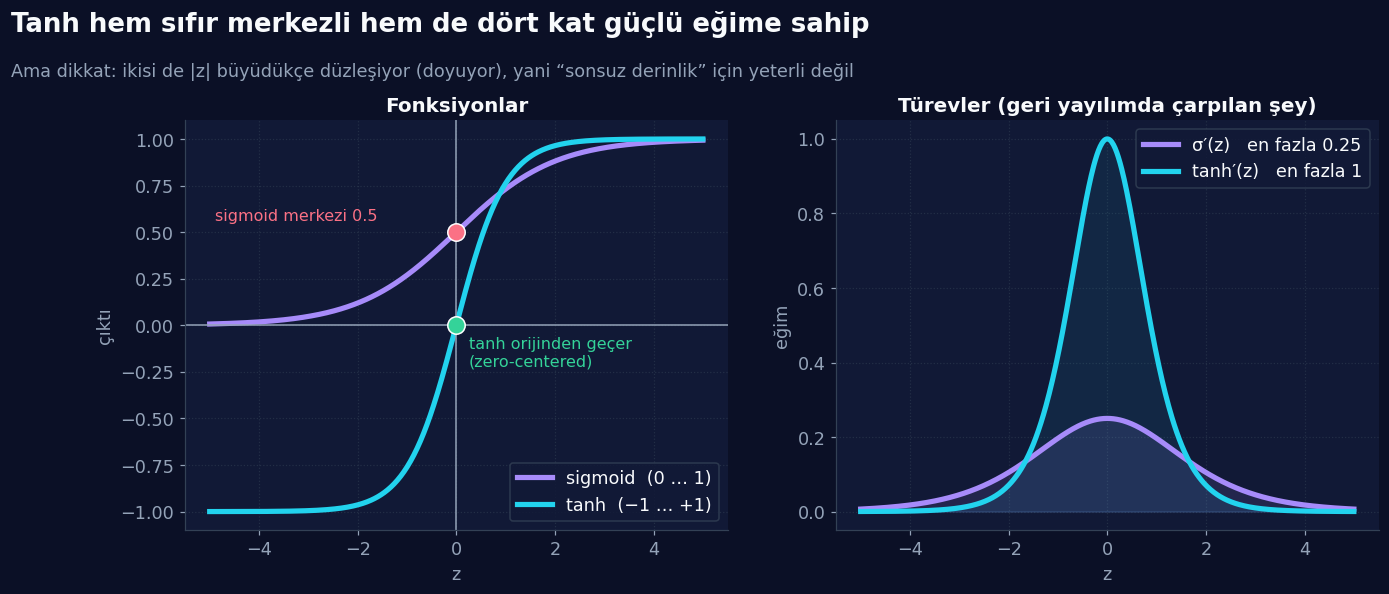

In [15]:
z_ekseni = np.linspace(-5, 5, 600)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.4))

ax1.plot(z_ekseni, sigmoid(z_ekseni), color=RENK['mor'], lw=3.4, label='sigmoid  (0 … 1)')
ax1.plot(z_ekseni, tanh(z_ekseni), color=RENK['cam'], lw=3.4, label='tanh  (−1 … +1)')
ax1.axhline(0, color=RENK['soluk'], lw=1); ax1.axvline(0, color=RENK['soluk'], lw=1)
ax1.scatter([0], [0], s=130, color=RENK['yesil'], edgecolor='white', zorder=5); ax1.text(0.25, -0.22, 'tanh orijinden geçer\n(zero-centered)', color=RENK['yesil'], fontsize=10.5)
ax1.scatter([0], [0.5], s=130, color=RENK['gul'], edgecolor='white', zorder=5); ax1.text(-4.9, 0.56, 'sigmoid merkezi 0.5', color=RENK['gul'], fontsize=10.5)
ax1.set_title('Fonksiyonlar'); ax1.set_xlabel('z'); ax1.set_ylabel('çıktı'); ax1.legend(loc='lower right')

ax2.plot(z_ekseni, sigmoid_turev(z_ekseni), color=RENK['mor'], lw=3.4, label='σ′(z)   en fazla 0.25')
ax2.plot(z_ekseni, tanh_turev(z_ekseni), color=RENK['cam'], lw=3.4, label='tanh′(z)   en fazla 1')
ax2.fill_between(z_ekseni, 0, sigmoid_turev(z_ekseni), color=RENK['mor'], alpha=0.12)
ax2.fill_between(z_ekseni, 0, tanh_turev(z_ekseni), color=RENK['cam'], alpha=0.08)
ax2.set_title('Türevler (geri yayılımda çarpılan şey)'); ax2.set_xlabel('z'); ax2.set_ylabel('eğim'); ax2.legend(loc='upper right')

baslik(fig, 'Tanh hem sıfır merkezli hem de dört kat güçlü eğime sahip',
       'Ama dikkat: ikisi de |z| büyüdükçe düzleşiyor (doyuyor), yani “sonsuz derinlik” için yeterli değil', ust=0.80)
kaydet(fig, '04_sigmoid_tanh_turev')

### ❓ Tanh Vanishing Gradient’i Tamamen Çözer mi?

Kaynağın cevabı kısa ve net: **Hayır.** Uzun cevap: derin bir ağda geri yayılım sırasında şöyle çarpımlar yapılır:

> `0.8 × 0.5 × 0.2 × 0.05 × …`

Bu değerler **başta makul görünür, katman sayısı arttıkça hızla küçülür.** Hesaplayalım ve sigmoid’in en iyi durumuyla yan yana koyalım:

In [16]:
tanh_ornek = np.array([0.8, 0.5, 0.2, 0.05])      # kaynaktaki örnek çarpanlar
sigmoid_en_iyi = np.full(4, 0.25)                  # sigmoid'in en iyi durumu
relu_poz = np.ones(4)                              # ReLU pozitif bölge (Bölüm 5)

zincir = pd.DataFrame({
    'Sigmoid (en iyi durum 0.25)': np.cumprod(sigmoid_en_iyi),
    'Tanh (kaynaktaki örnek)': np.cumprod(tanh_ornek),
    'ReLU (pozitif bölge)': np.cumprod(relu_poz),
}, index=[f'{k}. katmandan sonra' for k in range(1, 5)])
display(zincir)

# Tanh'ın türevi de uçlarda sönüyor (doyma)
print('\nTanh türevi farklı z için:')
for zn in [0, 1, 2, 3, 5]:
    print(f'  z = {zn}:  tanh′ = {tanh_turev(float(zn)):.5f}')
print(f'\n10 katmanın hepsi z = 2 civarında doymuşsa: tanh′(2)¹⁰ = {tanh_turev(2.0) ** 10:.1e}')

,Sigmoid (en iyi durum 0.25),Tanh (kaynaktaki örnek),ReLU (pozitif bölge)
1. katmandan sonra,0.250000,0.800,1.0
2. katmandan sonra,0.062500,0.400,1.0
3. katmandan sonra,0.015625,0.080,1.0
4. katmandan sonra,0.003906,0.004,1.0



Tanh türevi farklı z için:
  z = 0:  tanh′ = 1.00000
  z = 1:  tanh′ = 0.41997
  z = 2:  tanh′ = 0.07065
  z = 3:  tanh′ = 0.00987
  z = 5:  tanh′ = 0.00018

10 katmanın hepsi z = 2 civarında doymuşsa: tanh′(2)¹⁰ = 3.1e-12


<p align="center"><img src="assets/turev_zinciri.svg" width="100%" alt="Animasyon: gradyan geri giderken sigmoid ve tanh'ta sönüyor, ReLU'da korunuyor"></p>

Animasyonda her daire, o katmana ulaşan **gradyanın büyüklüğü.** Işık huzmesi çıktıdan girdiye ilerlerken sigmoid’de ve tanh’ta **sönüyor**; ReLU’da (Bölüm 5) ise **korunuyor.**

Kaynağın sonucu: **Tanh, vanishing gradient problemini azaltır ama tamamen ortadan kaldırmaz.**

<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="dikkat">

**Dürüst bir not (Bölüm 10’da deneyle göreceğiz):** Tanh’ın gradyanı **doymuş** (|z| büyük) nöronlarda sönüyor; ağırlıklar **akıllıca başlatıldığında** ise 10 katmanlı küçük bir ağda tanh’ın gradyanı bizim deneyimizde **sağlıklı kaldı.** Yani “tanh derinlikte mutlaka çöker” değil, **“sigmoid’den çok daha geç ve çok daha az çöker; ama doyma ve kötü başlatma varsa yine sönebilir.”** Bu yüzden derin ağlar için asıl çözüm **ReLU ailesi.**

</td></tr></table>

In [17]:
karsilastirma = pd.DataFrame({
    'Sigmoid': ['(0, 1)', 'Hayır', '0.25', 'Daha erken'],
    'Tanh': ['(−1, +1)', 'Evet', '1', 'Daha geç'],
}, index=['Çıktı aralığı', 'Zero-centered mi?', 'Maksimum türev', 'Vanishing gradient başlar']).rename_axis('Özellik')
display(karsilastirma)

,Sigmoid,Tanh
Özellik,,
Çıktı aralığı,"(0, 1)","(−1, +1)"
Zero-centered mi?,Hayır,Evet
Maksimum türev,0.25,1
Vanishing gradient başlar,Daha erken,Daha geç


### ⚖️ Tanh’ın Terazisi

<table><tr>
<td width="50%" valign="top"><h4>✅ Avantajları</h4><ul><li>Zero-centered çıktı</li><li>Sigmoid’e göre daha güçlü gradyan</li><li>Orta derinlikteki ağlar için uygun</li></ul></td>
<td width="50%" valign="top"><h4>⚠️ Dezavantajları</h4><ul><li>Derin ağlarda hâlâ vanishing gradient riski</li><li>Üstel (exponential) işlemler içerir</li><li>Hesaplama maliyeti yüksektir</li></ul></td>
</tr></table>

<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="sonuc">

**Özet (kaynakla):** Tanh, sigmoid’in **geliştirilmiş bir versiyonudur**; zero-centered olduğu için **daha verimlidir**; ama **derin ağlar için hâlâ yeterli değildir.** Bu eksiklikler bizi bir sonraki fonksiyona götürüyor: **ReLU (Rectified Linear Unit)**, derin öğrenmeyi gerçekten mümkün kılan fonksiyon.

</td></tr></table>

<a id="b5"></a>

<p align="center"><img src="assets/bolum_05.svg" width="100%" alt="Bölüm 5 — ReLU"></p>

### 🎭 Benzetme: Tek Yönlü Turnike

Sigmoid ve tanh derin ağlarda şu sorunları yaşatıyordu (kaynak): **vanishing gradient**, ağırlıkların **yeterince güncellenememesi**, eğitimin **çok yavaşlaması ya da durması.** Bunları çözmek için geliştirilen en önemli fonksiyonlardan biri: **ReLU (Rectified Linear Unit).**

ReLU **son derece basittir:**

> **ReLU(x) = max(0, x)**

Yani: `x > 0` ise çıktı **x** (aynen geçer); `x ≤ 0` ise çıktı **0.**

🎭 **Benzetme:** Metro girişindeki **tek yönlü turnike.** İleri yönde geçen yolcu (pozitif sayı) **aynen geçer**; geri yönde gelen (negatif sayı) **kapıda durdurulur** ve sıfırlanır. Ya da **fatura mantığı:** alacağın varsa tamamını al, borcun varsa “bugün ödeme yok” (0) de.

<p align="center"><img src="assets/relu_anim.svg" width="100%" alt="Animasyon: ReLU turnikesi, negatifler sıfırlanır, pozitifler aynen geçer"></p>

In [18]:
xr = np.array([-4, -2, -0.5, 0, 0.5, 2, 4], dtype=float)
display(pd.DataFrame({'x': xr, 'ReLU(x) = max(0, x)': relu(xr), 'Türev ReLU′(x)': relu_turev(xr)}).set_index('x'))

,"ReLU(x) = max(0, x)",Türev ReLU′(x)
x,,
-4.0,0.0,0.0
-2.0,0.0,0.0
-0.5,0.0,0.0
0.0,0.0,0.0
0.5,0.5,1.0
2.0,2.0,1.0
4.0,4.0,1.0


### 📐 ReLU’nun Türevi: Gradyan Kaybolmuyor

Kaynağa göre ReLU’nun türevi:

> **ReLU′(x) = 1** (x > 0 ise)  ·  **ReLU′(x) = 0** (x ≤ 0 ise)

Bu şu anlama gelir: **pozitif bölgede gradyan kaybolmaz**; türev **tam 1** olduğu için geri yayılımda çarpıldığında sinyali **küçültmez.** Fısıltı oyunu benzetmesiyle: *her oyuncu mesajı aynı ses seviyesinde iletir.* Bu yüzden **vanishing gradient problemi büyük ölçüde çözülür.**

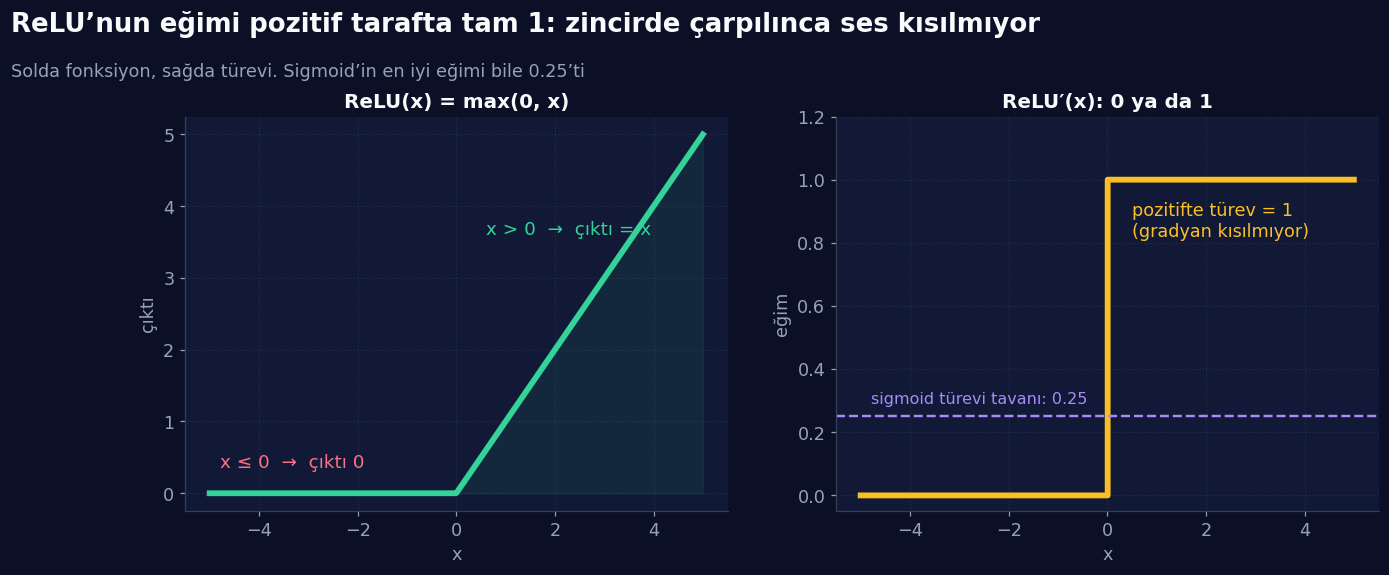

In [19]:
xr_c = np.linspace(-5, 5, 600)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))
ax1.plot(xr_c, relu(xr_c), color=RENK['yesil'], lw=3.8)
ax1.fill_between(xr_c, 0, relu(xr_c), color=RENK['yesil'], alpha=0.08)
ax1.text(-4.8, 0.35, 'x ≤ 0  →  çıktı 0', color=RENK['gul'], fontsize=12); ax1.text(0.6, 3.6, 'x > 0  →  çıktı = x', color=RENK['yesil'], fontsize=12)
ax1.set_title('ReLU(x) = max(0, x)'); ax1.set_xlabel('x'); ax1.set_ylabel('çıktı')
ax2.step(xr_c, relu_turev(xr_c), where='post', color=RENK['amber'], lw=3.8)
ax2.axhline(0.25, color=RENK['mor'], lw=1.6, ls='--'); ax2.text(-4.8, 0.29, 'sigmoid türevi tavanı: 0.25', color=RENK['mor'], fontsize=10.5)
ax2.text(0.5, 0.82, 'pozitifte türev = 1\n(gradyan kısılmıyor)', color=RENK['amber'], fontsize=11.5)
ax2.set_ylim(-0.05, 1.2); ax2.set_title('ReLU′(x): 0 ya da 1'); ax2.set_xlabel('x'); ax2.set_ylabel('eğim')
baslik(fig, 'ReLU’nun eğimi pozitif tarafta tam 1: zincirde çarpılınca ses kısılmıyor',
       'Solda fonksiyon, sağda türevi. Sigmoid’in en iyi eğimi bile 0.25’ti', ust=0.80)
kaydet(fig, '05_relu')

### ✅ ReLU’nun Avantajları

- **Vanishing gradient problemini büyük ölçüde çözer,**
- **Hesaplama olarak çok hızlıdır** (üstel işlem yok, sadece “0’la karşılaştır”),
- **Modern derin ağların temelidir.**

Bu yüzden **ReLU, derin öğrenmeyi gerçekten mümkün kılmıştır.**

### 💀 ReLU’nun Problemi: Ölü Nöron (Dead Neuron)

ReLU’nun ciddi bir sorunu da var. Kaynak şöyle diyor: *eğer bir nöron sürekli negatif değer alıyorsa, çıktısı hep 0 olur.* Bu durumda:

- **Türevi 0 olur,**
- **Ağırlıklar güncellenmez,**
- **Nöron tamamen “ölür.”**

Bu duruma **Dead ReLU (Dead Neuron) Problemi** denir.

> 🎭 **Benzetme:** Şalteri bir kez kapanan ve **kapanınca bir daha asla açılamayan** bir makine. Açma düğmesi (gradyan) devre dışı olduğu için kimse müdahale edemiyor.

### 🧪 Ek Örnek (kaynakta yok): Ölü Nöronu Canlı Yayında İzleyelim

Tek bir ReLU nöronu `ŷ = ReLU(w·x + b)` düşün; hedefimiz basit bir fonksiyonu öğrenmek. Normal eğitim çalışırken, **30. adımda** aşırı büyük bir güncelleme (örneğin çok yüksek öğrenme oranından gelen bir sıçrama) bias’ı **−6 birim** aşağı itsin. (Bu sıçramayı **kendimiz simüle ediyoruz**; gerçek eğitimde sebebi yüksek learning rate ya da kötü başlatma olabilir.) Sonrasında nöron yeniden toparlanabilecek mi?

In [20]:
def olu_noron_deneyi(f, f_turev, adim=400, lr=0.05, tekme_adim=30, tekme=-6.0):
    """Tek nöron ŷ = f(w·x + b). 30. adımda bias'a büyük bir negatif sıçrama (simülasyon) uygulanır."""
    r = np.random.default_rng(0)
    x = r.normal(0, 1, 100)
    hedef = 2 * np.maximum(0, x) + 0.5                  # öğrenilecek fonksiyon
    w, b = 1.0, 0.2
    kayip_, aktif_ = [], []
    for t in range(adim):
        if t == tekme_adim:
            b += tekme                                    # simüle edilen büyük sıçrama
        z = w * x + b
        e = f(z) - hedef
        kayip_.append((e ** 2).mean()); aktif_.append((z > 0).mean())
        g = 2 * e * f_turev(z) / len(x)                   # zincir kuralı: türev 0 ise gradyan 0!
        w -= lr * (g * x).sum(); b -= lr * g.sum()
    return np.array(kayip_), np.array(aktif_), w, b

L_relu, aktif_relu, w_r, b_r = olu_noron_deneyi(relu, relu_turev)
print(f'29. adımda (sıçrama öncesi) kayıp = {L_relu[29]:.3f},  aktif örnek oranı = {aktif_relu[29]:.2f}')
print(f'31. adımda (sıçrama sonrası) kayıp = {L_relu[31]:.3f},  aktif örnek oranı = {aktif_relu[31]:.2f}')
print(f'400. adımda                 kayıp = {L_relu[-1]:.3f},  aktif örnek oranı = {aktif_relu[-1]:.2f}   (w = {w_r:.2f}, b = {b_r:.2f})')
assert aktif_relu[-1] == 0 and abs(L_relu[31] - L_relu[-1]) < 1e-12, 'ReLU nöronu sıçramadan sonra kıpırdamamalıydı'
print('✅ ReLU nöronu 370 adım boyunca hiç değişmedi: ağırlık ve bias aynı, kayıp aynı → nöron ÖLDÜ.')

29. adımda (sıçrama öncesi) kayıp = 0.110,  aktif örnek oranı = 0.68
31. adımda (sıçrama sonrası) kayıp = 3.291,  aktif örnek oranı = 0.00
400. adımda                 kayıp = 3.291,  aktif örnek oranı = 0.00   (w = 1.68, b = -5.22)
✅ ReLU nöronu 370 adım boyunca hiç değişmedi: ağırlık ve bias aynı, kayıp aynı → nöron ÖLDÜ.


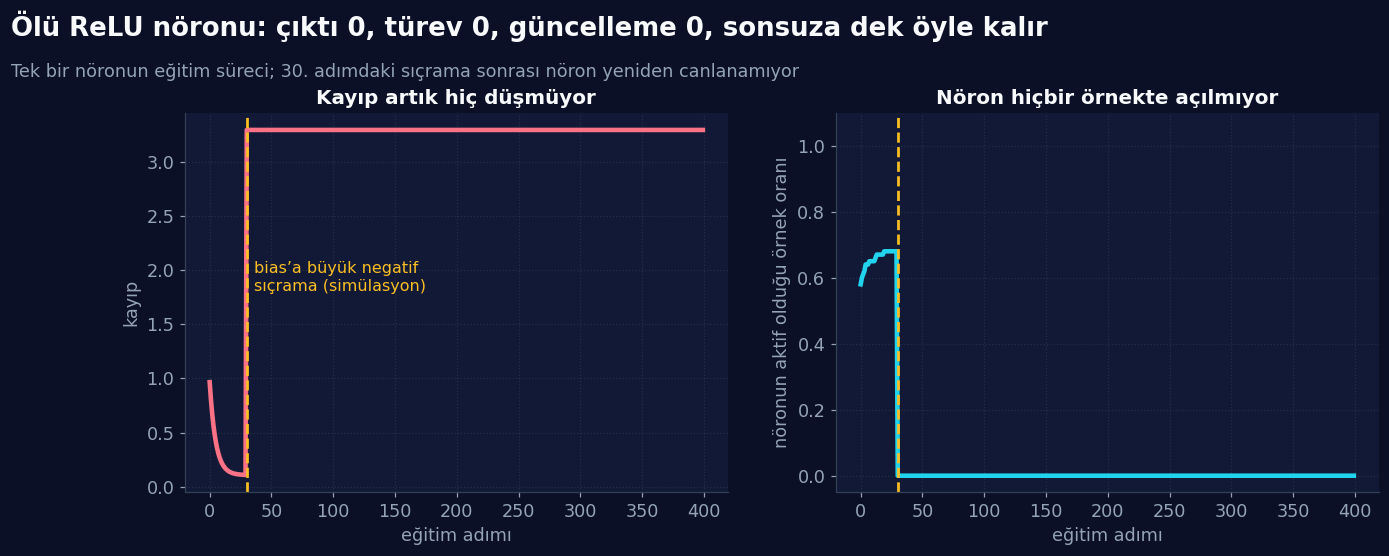

In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.0))
adim_ekseni = np.arange(len(L_relu))
ax1.plot(adim_ekseni, L_relu, color=RENK['gul'], lw=3)
ax1.axvline(30, color=RENK['amber'], ls='--', lw=1.8); ax1.text(36, L_relu[31] * 0.55, 'bias’a büyük negatif\nsıçrama (simülasyon)', color=RENK['amber'], fontsize=10.5)
ax1.set_xlabel('eğitim adımı'); ax1.set_ylabel('kayıp'); ax1.set_title('Kayıp artık hiç düşmüyor')
ax2.plot(adim_ekseni, aktif_relu, color=RENK['cam'], lw=3)
ax2.axvline(30, color=RENK['amber'], ls='--', lw=1.8)
ax2.set_xlabel('eğitim adımı'); ax2.set_ylabel('nöronun aktif olduğu örnek oranı'); ax2.set_ylim(-0.05, 1.1); ax2.set_title('Nöron hiçbir örnekte açılmıyor')
baslik(fig, 'Ölü ReLU nöronu: çıktı 0, türev 0, güncelleme 0, sonsuza dek öyle kalır',
       'Tek bir nöronun eğitim süreci; 30. adımdaki sıçrama sonrası nöron yeniden canlanamıyor', ust=0.80)
kaydet(fig, '05_olu_noron')

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="icgoru">

**Çıkarım:** ReLU’nun gücü (negatifleri sıfırlaması) aynı zamanda zayıflığıdır. Türev 0 olduğu anda **öğrenme sinyali de 0** olur. Çözüm: negatif bölgeyi **tamamen kapatmamak.** Bir sonraki bölümün konusu bu.

</td></tr></table>

<a id="b6"></a>

<p align="center"><img src="assets/bolum_06.svg" width="100%" alt="Bölüm 6 — Leaky ReLU ve Parametric ReLU"></p>

### 🎭 Benzetme: Yangın Kapısının Altındaki Aralık

ReLU negatif tarafta kapıyı **tamamen** kapatıyordu. **Leaky ReLU** ise kapıyı **tam kapatmaz, altında küçük bir aralık bırakır**: negatif tarafta da **küçücük bir sinyal sızar** (İngilizce *leaky = sızıntı yapan*). Musluğun tamamen kapalı olması yerine **damlıyor** gibi düşün.

> **Leaky ReLU(x) = x**  (x > 0 ise)  ·  **α · x**  (x ≤ 0 ise)

Burada **α** (alfa) genellikle **0.01**’dir, yani negatif tarafta girdinin **%1’i** kadar sinyal geçer.

**Leaky ReLU ne sağlar?** (kaynak)

- Negatif bölgede **türev sıfır olmaz** (türev = α),
- **Dead neuron problemi büyük ölçüde çözülür,**
- ReLU’nun **hız avantajı korunur.**

### 🎛️ Parametric ReLU (PReLU): Aralığı Ayarlamayı Model Öğrensin

PReLU, Leaky ReLU’nun **bir adım ötesidir**: formül aynı, **ama α sabit değildir, eğitim sırasında öğrenilir.**

> **PReLU(x) = x**  (x > 0 ise)  ·  **α · x**  (x ≤ 0 ise),  *α modelin kendisi tarafından öğrenilir.*

🎭 *Kapının altındaki aralığın kaç santim olacağına bina yöneticisi (sen) değil, sistemin kendisi karar veriyor.*

<table><tr>
<td width="50%" valign="top"><h4>✅ PReLU Avantajları</h4><ul><li>Dead neuron problemi yok</li><li>Daha esnek bir yapı</li><li>Özellikle <b>CNN</b>’lerde etkili</li></ul></td>
<td width="50%" valign="top"><h4>⚠️ PReLU Dezavantajı</h4><ul><li><b>Ek parametre</b> öğrenilir</li><li><b>Overfitting</b> (ezberleme) riski artabilir</li></ul></td>
</tr></table>

In [22]:
xl = np.array([-4, -2, -1, 0, 1, 3], dtype=float)
display(pd.DataFrame({'x': xl, 'ReLU': relu(xl), 'Leaky (α=0.01)': leaky_relu(xl, 0.01), 'Leaky (α=0.1)': leaky_relu(xl, 0.1),
                      'Türev ReLU': relu_turev(xl), 'Türev Leaky(0.01)': leaky_relu_turev(xl, 0.01)}).set_index('x'))

,ReLU,Leaky (α=0.01),Leaky (α=0.1),Türev ReLU,Türev Leaky(0.01)
x,,,,,
-4.0,0.0,-0.04,-0.4,0.0,0.01
-2.0,0.0,-0.02,-0.2,0.0,0.01
-1.0,0.0,-0.01,-0.1,0.0,0.01
0.0,0.0,0.00,0.0,0.0,0.01
1.0,1.0,1.00,1.0,1.0,1.00
3.0,3.0,3.00,3.0,1.0,1.00


### 🧪 Ek Örnek (kaynakta yok): PReLU α’yı Gerçekten Öğreniyor mu?

Bir sınama kuralı kuralım: gerçek dünya **α = 0.2’lik bir Leaky ReLU gibi davransın** (biz biliyoruz ama model bilmiyor). Üzerine biraz gürültü ekleyip 400 örnek üretelim. PReLU’yu **α = 0.01** ile başlatıp sadece α’yı gradyan inişiyle öğretelim. Gerçek değere ulaşabilecek mi?

Not: `α` için türev şöyle gelir: `x ≤ 0` iken `PReLU = α·x`, dolayısıyla `∂PReLU/∂α = x`; `x > 0` iken `0`.

In [23]:
rng = np.random.default_rng(0)
x_p = rng.normal(0, 2, 400)
alfa_gercek = 0.2
y_p = np.where(x_p > 0, x_p, alfa_gercek * x_p) + rng.normal(0, 0.02, 400)

alfa = 0.01; alfa_gecmis = [alfa]
for _ in range(300):
    tahmin = np.where(x_p > 0, x_p, alfa * x_p)
    hata = tahmin - y_p
    g_alfa = (2 * hata * np.where(x_p > 0, 0.0, x_p)).mean()      # ∂L/∂α
    alfa -= 0.05 * g_alfa
    alfa_gecmis.append(alfa)
alfa_gecmis = np.array(alfa_gecmis)
print(f'Başlangıç α = {alfa_gecmis[0]:.3f}  →  300 adım sonra α = {alfa_gecmis[-1]:.4f}   (gerçek α = {alfa_gercek})')
assert abs(alfa_gecmis[-1] - alfa_gercek) < 0.01

Başlangıç α = 0.010  →  300 adım sonra α = 0.2005   (gerçek α = 0.2)


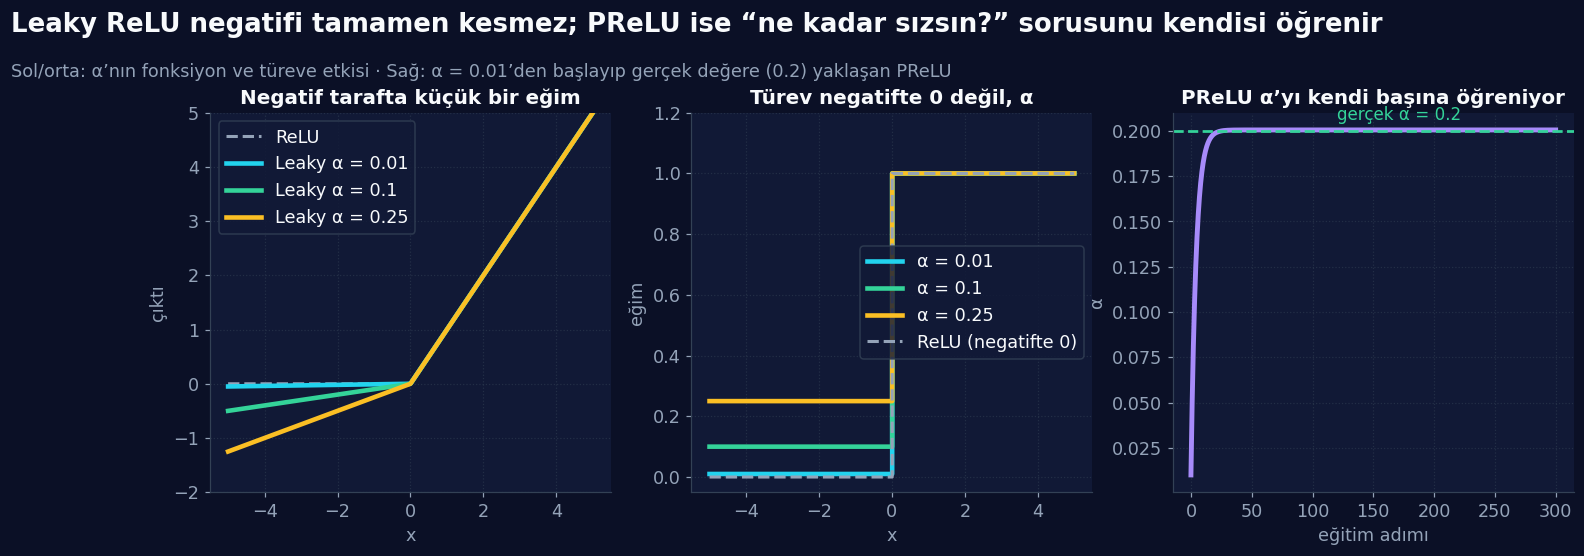

In [24]:
xl_c = np.linspace(-5, 5, 600)
fig, eksenler = plt.subplots(1, 3, figsize=(16, 5.0))

ax = eksenler[0]
ax.plot(xl_c, relu(xl_c), color=RENK['soluk'], lw=2, ls='--', label='ReLU')
for a_, renk in [(0.01, RENK['cam']), (0.1, RENK['yesil']), (0.25, RENK['amber'])]:
    ax.plot(xl_c, leaky_relu(xl_c, a_), color=renk, lw=3, label=f'Leaky α = {a_}')
ax.set_ylim(-2, 5); ax.set_title('Negatif tarafta küçük bir eğim'); ax.set_xlabel('x'); ax.set_ylabel('çıktı'); ax.legend(loc='upper left')

ax = eksenler[1]
for a_, renk in [(0.01, RENK['cam']), (0.1, RENK['yesil']), (0.25, RENK['amber'])]:
    ax.step(xl_c, leaky_relu_turev(xl_c, a_), where='post', color=renk, lw=3, label=f'α = {a_}')
ax.step(xl_c, relu_turev(xl_c), where='post', color=RENK['soluk'], lw=2, ls='--', label='ReLU (negatifte 0)')
ax.set_ylim(-0.05, 1.2); ax.set_title('Türev negatifte 0 değil, α'); ax.set_xlabel('x'); ax.set_ylabel('eğim'); ax.legend(loc='center right')

ax = eksenler[2]
ax.plot(alfa_gecmis, color=RENK['mor'], lw=3.2)
ax.axhline(alfa_gercek, color=RENK['yesil'], ls='--', lw=1.8); ax.text(120, alfa_gercek + 0.006, 'gerçek α = 0.2', color=RENK['yesil'], fontsize=11)
ax.set_title('PReLU α’yı kendi başına öğreniyor'); ax.set_xlabel('eğitim adımı'); ax.set_ylabel('α')

baslik(fig, 'Leaky ReLU negatifi tamamen kesmez; PReLU ise “ne kadar sızsın?” sorusunu kendisi öğrenir',
       'Sol/orta: α’nın fonksiyon ve türeve etkisi · Sağ: α = 0.01’den başlayıp gerçek değere (0.2) yaklaşan PReLU', ust=0.80)
kaydet(fig, '06_leaky_prelu')

### 🧪 Ölü Nöron Deneyini Tekrarlayalım: Leaky Kurtarıyor mu?

Bölüm 5’teki **aynı deneyi** (30. adımda aynı büyük sıçrama) bu sefer üç aktivasyonla çalıştıralım: **ReLU**, **Leaky ReLU (α = 0.01)** ve **Leaky ReLU (α = 0.1)**:

,Sıçrama sonrası kayıp (31. adım),Son kayıp (400. adım),Son aktif örnek oranı
ReLU,3.291,3.291,0.00
Leaky α=0.01,3.400,3.376,0.00
Leaky α=0.1,4.619,0.177,0.59


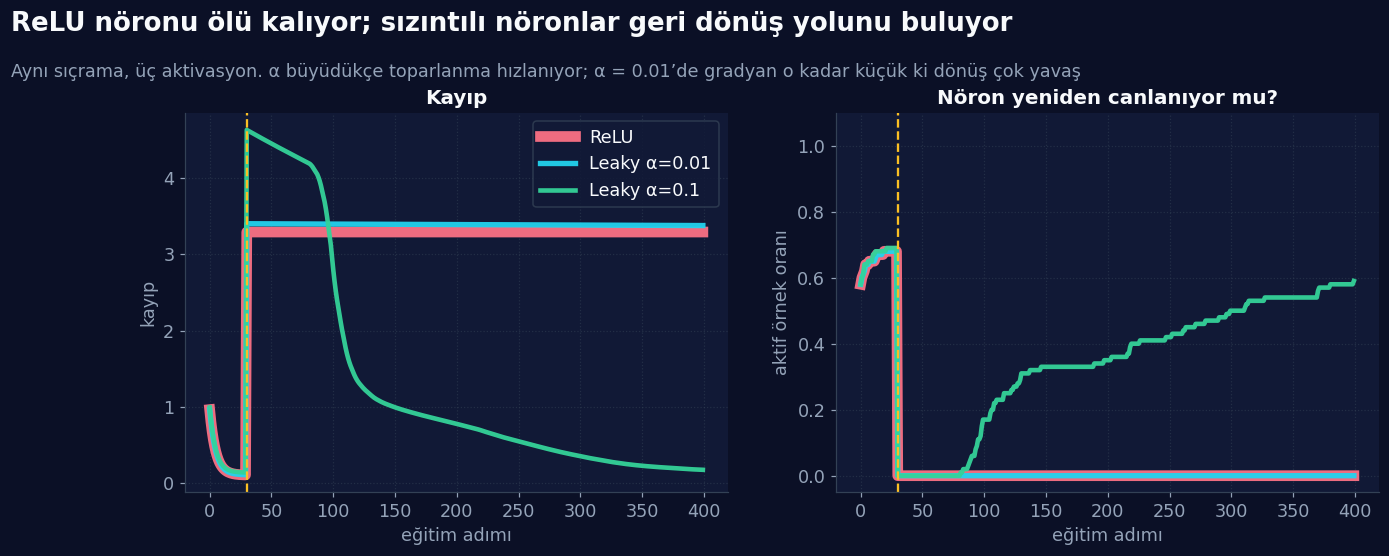

In [25]:
sonuclar = {}
for ad, (f, df) in {'ReLU': (relu, relu_turev),
                    'Leaky α=0.01': (lambda z: leaky_relu(z, 0.01), lambda z: leaky_relu_turev(z, 0.01)),
                    'Leaky α=0.1': (lambda z: leaky_relu(z, 0.1), lambda z: leaky_relu_turev(z, 0.1))}.items():
    sonuclar[ad] = olu_noron_deneyi(f, df)

ozet = pd.DataFrame({ad: {'Sıçrama sonrası kayıp (31. adım)': L[31], 'Son kayıp (400. adım)': L[-1], 'Son aktif örnek oranı': a[-1]}
                     for ad, (L, a, w_, b_) in sonuclar.items()}).T
display(ozet.round(3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.0))
for (ad, (L, a, w_, b_)), renk, kal in zip(sonuclar.items(), [RENK['gul'], RENK['cam'], RENK['yesil']], [7, 3.5, 3]):
    ax1.plot(L, color=renk, lw=kal, label=ad, alpha=0.95); ax2.plot(a, color=renk, lw=kal, label=ad, alpha=0.95)   # ReLU kalın çizildi: Leaky α=0.01’in altında kalmasın
ax1.axvline(30, color=RENK['amber'], ls='--', lw=1.5); ax2.axvline(30, color=RENK['amber'], ls='--', lw=1.5)
ax1.set_xlabel('eğitim adımı'); ax1.set_ylabel('kayıp'); ax1.set_title('Kayıp'); ax1.legend()
ax2.set_xlabel('eğitim adımı'); ax2.set_ylabel('aktif örnek oranı'); ax2.set_title('Nöron yeniden canlanıyor mu?'); ax2.set_ylim(-0.05, 1.1)
baslik(fig, 'ReLU nöronu ölü kalıyor; sızıntılı nöronlar geri dönüş yolunu buluyor',
       'Aynı sıçrama, üç aktivasyon. α büyüdükçe toparlanma hızlanıyor; α = 0.01’de gradyan o kadar küçük ki dönüş çok yavaş', ust=0.80)
kaydet(fig, '06_olu_noron_cozum')

<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="dikkat">

**Dürüst bir okuma:** ReLU nöronu **kesinlikle** takılı kaldı (aktif örnek oranı 0, kayıp hiç değişmedi). **Leaky ReLU (α = 0.01)** teknik olarak ölü değil, çünkü türev 0 değil; ama gradyan o kadar küçük ki bu deneyde 370 adımda **neredeyse hiç toparlanamadı.** **α = 0.1** ile nöron canlandı. Yani Leaky ReLU **kurtuluş yolunu açık tutar**, ne kadar hızlı kurtulacağı ise α’ya ve öğrenme oranına bağlıdır. PReLU’nun α’yı öğrenmesinin mantığı da budur.

</td></tr></table>

<a id="b7"></a>

<p align="center"><img src="assets/bolum_07.svg" width="100%" alt="Bölüm 7 — GELU"></p>

### 🎭 Benzetme: Sert Baraj mı, Olasılıklı Geçiş mi?

**GELU (Gaussian Error Linear Unit)**, kaynağa göre **modern transformer tabanlı modellerde (BERT, GPT vb.) en sık kullanılan** aktivasyon fonksiyonudur. Sezgisel tanımı:

> **“Bir değeri tamamen kapatmak yerine, olasılıksal olarak geçirir.”**

Yani **ReLU gibi sert bir eşik yoktur.** İki kapıcıyı karşılaştır:

| Kapıcı | Davranışı | Örnek |
|:--|:--|:--|
| 🚪 **ReLU kapıcısı** | “Negatifsen **kesinlikle** giremezsin.” | −0.2 gelir → **0** |
| 🎲 **GELU kapıcısı** | “Girişin ne kadar güçlüyse **o oranda** girersin.” | −0.2 gelir → küçük bir kısmı geçer |

Matematiksel tanım:

> **GELU(x) = x · Φ(x)**

Burada **Φ(x)** (fi), **standart normal dağılımın kümülatif dağılım fonksiyonudur (CDF).** Gözünün korkmasın: Φ(x), çan eğrisinde **x’in solunda kalan alan**dır, yani *“standart bir rastgele sayının x’ten küçük olma olasılığı.”* 0 ile 1 arasındadır ve x büyüdükçe 1’e yaklaşır. Böylece **Φ(x) bir “geçirme olasılığı”** gibi çalışır, ve GELU girdiyi o olasılıkla çarpar.

In [26]:
erf_v = np.vectorize(math.erf)

def normal_cdf(x):
    """Φ(x): standart normal dağılımın kümülatif dağılım fonksiyonu (CDF)."""
    return 0.5 * (1.0 + erf_v(np.asarray(x, dtype=float) / math.sqrt(2.0)))

def gelu_tam(x):
    return np.asarray(x, dtype=float) * normal_cdf(x)

xg = np.array([-3, -2, -1, -0.5, 0, 0.5, 1, 2, 3], dtype=float)
tablo_gelu = pd.DataFrame({'x': xg, 'Φ(x) geçirme olasılığı': normal_cdf(xg), 'GELU = x·Φ(x)': gelu_tam(xg),
                           'ReLU': relu(xg), 'GELU (tanh yaklaşığı)': gelu(xg)}).set_index('x')
display(tablo_gelu.round(4))

print(f'x = +1 → Φ = {normal_cdf(1.0):.3f}: değerin %{normal_cdf(1.0) * 100:.0f}’i geçiyor → GELU = {gelu_tam(1.0):.3f}')
print(f'x = −1 → Φ = {normal_cdf(-1.0):.3f}: değerin %{normal_cdf(-1.0) * 100:.0f}’i geçiyor → GELU = {gelu_tam(-1.0):.3f}   (ReLU burada tam 0 verirdi)')

,Φ(x) geçirme olasılığı,GELU = x·Φ(x),ReLU,GELU (tanh yaklaşığı)
x,,,,
-3.0,0.0013,-0.0040,0.0,-0.0036
-2.0,0.0228,-0.0455,0.0,-0.0454
-1.0,0.1587,-0.1587,0.0,-0.1588
-0.5,0.3085,-0.1543,0.0,-0.1543
0.0,0.5000,0.0000,0.0,0.0000
0.5,0.6915,0.3457,0.5,0.3457
1.0,0.8413,0.8413,1.0,0.8412
2.0,0.9772,1.9545,2.0,1.9546
3.0,0.9987,2.9960,3.0,2.9964


x = +1 → Φ = 0.841: değerin %84’i geçiyor → GELU = 0.841
x = −1 → Φ = 0.159: değerin %16’i geçiyor → GELU = -0.159   (ReLU burada tam 0 verirdi)


### 🧮 Pratikte Kullanılan Yaklaşık Form

Φ(x)’i her seferinde tam hesaplamak pahalı olduğu için pratikte şu **yaklaşık formül** kullanılır (kaynakla aynı):

> **GELU(x) ≈ 0.5 · x · (1 + tanh( √(2/π) · (x + 0.044715·x³) ))**

Bu yaklaşık form ne kadar iyi? Kendi kodumuzla ölçelim, ayrıca türevimizi sayısal türevle doğrulayalım:

In [27]:
xs = np.linspace(-6, 6, 2001)
fark = np.abs(gelu(xs) - gelu_tam(xs))
print(f'Tanh yaklaşığı ile tam GELU arasındaki en büyük fark: {fark.max():.5f}  (yani 0.0005’ten küçük)')

# GELU'nun en düşük noktası: negatif tarafta küçük bir "çukur" var
xn = np.linspace(-4, 0, 40001)
cukur = gelu_tam(xn)
print(f'GELU’nun en düşük değeri: {cukur.min():.3f}  (x ≈ {xn[cukur.argmin()]:.2f} noktasında)')

# Türev doğrulaması (kendi kodumuzu sınıyoruz): analitik türev ≈ sayısal türev mi?
h = 1e-6
sayisal = (gelu(xs + h) - gelu(xs - h)) / (2 * h)
print(f'Türev kontrolü: en büyük fark = {np.abs(sayisal - gelu_turev(xs)).max():.1e}')
assert fark.max() < 1e-3 and np.abs(sayisal - gelu_turev(xs)).max() < 1e-6
print('✅ Yaklaşık GELU ve türevi doğrulandı.')

Tanh yaklaşığı ile tam GELU arasındaki en büyük fark: 0.00047  (yani 0.0005’ten küçük)
GELU’nun en düşük değeri: -0.170  (x ≈ -0.75 noktasında)
Türev kontrolü: en büyük fark = 8.3e-10
✅ Yaklaşık GELU ve türevi doğrulandı.


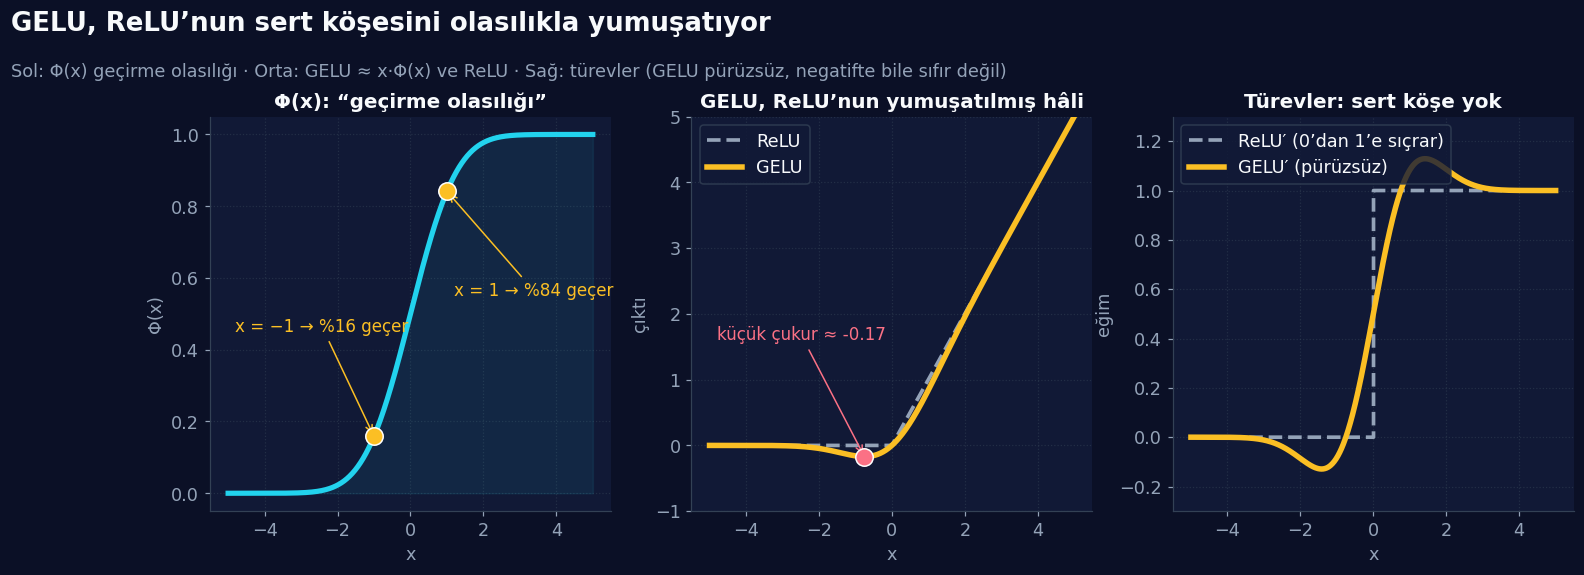

In [28]:
xg_c = np.linspace(-5, 5, 800)
fig, eksenler = plt.subplots(1, 3, figsize=(16, 5.2))

ax = eksenler[0]
ax.plot(xg_c, normal_cdf(xg_c), color=RENK['cam'], lw=3.4)
ax.fill_between(xg_c, 0, normal_cdf(xg_c), color=RENK['cam'], alpha=0.08)
ax.scatter([1, -1], [normal_cdf(1), normal_cdf(-1)], s=130, color=RENK['amber'], edgecolor='white', zorder=5)
ax.annotate('x = 1 → %84 geçer', (1, normal_cdf(1)), xytext=(1.2, 0.55), color=RENK['amber'], fontsize=11, arrowprops=dict(arrowstyle='->', color=RENK['amber']))
ax.annotate('x = −1 → %16 geçer', (-1, normal_cdf(-1)), xytext=(-4.8, 0.45), color=RENK['amber'], fontsize=11, arrowprops=dict(arrowstyle='->', color=RENK['amber']))
ax.set_title('Φ(x): “geçirme olasılığı”'); ax.set_xlabel('x'); ax.set_ylabel('Φ(x)')

ax = eksenler[1]
ax.plot(xg_c, relu(xg_c), color=RENK['soluk'], lw=2.4, ls='--', label='ReLU')
ax.plot(xg_c, gelu_tam(xg_c), color=RENK['amber'], lw=3.6, label='GELU')
ax.scatter([xn[cukur.argmin()]], [cukur.min()], s=130, color=RENK['gul'], edgecolor='white', zorder=5)
ax.annotate(f'küçük çukur ≈ {cukur.min():.2f}', (xn[cukur.argmin()], cukur.min()), xytext=(-4.8, 1.6), color=RENK['gul'], fontsize=11, arrowprops=dict(arrowstyle='->', color=RENK['gul']))
ax.set_ylim(-1, 5); ax.set_title('GELU, ReLU’nun yumuşatılmış hâli'); ax.set_xlabel('x'); ax.set_ylabel('çıktı'); ax.legend(loc='upper left')

ax = eksenler[2]
ax.step(xg_c, relu_turev(xg_c), where='post', color=RENK['soluk'], lw=2.4, ls='--', label='ReLU′ (0’dan 1’e sıçrar)')
ax.plot(xg_c, gelu_turev(xg_c), color=RENK['amber'], lw=3.6, label='GELU′ (pürüzsüz)')
ax.set_ylim(-0.3, 1.3); ax.set_title('Türevler: sert köşe yok'); ax.set_xlabel('x'); ax.set_ylabel('eğim'); ax.legend(loc='upper left')

baslik(fig, 'GELU, ReLU’nun sert köşesini olasılıkla yumuşatıyor',
       'Sol: Φ(x) geçirme olasılığı · Orta: GELU ≈ x·Φ(x) ve ReLU · Sağ: türevler (GELU pürüzsüz, negatifte bile sıfır değil)', ust=0.80)
kaydet(fig, '07_gelu')

### 🔍 GELU Neden Güçlü? (Kaynağa Göre)

- **ReLU gibi hızlı** (pozitif tarafta neredeyse `x` gibi davranır),
- **Tanh gibi yumuşak** (sert köşe yok, türev pürüzsüz),
- **Gradient akışı çok stabil,**
- **Transformer mimarileri için ideal** (BERT, GPT).

Küçük bir bedeli de var: `erf` ya da `tanh` hesabı gerektirdiği için **ReLU’dan biraz daha yavaştır** (Bölüm 10’da ölçeceğiz).

### 📋 ReLU Ailesi ve GELU: Kısa Karşılaştırma

In [29]:
ailesi = pd.DataFrame({
    'ReLU':        ['max(0, x)',           'Pozitifte türev 1 → büyük ölçüde çözülür', 'VAR (negatifte türev 0)',          'Yok',              'Çok hızlı',  'Çok yaygın'],
    'Leaky ReLU':  ['x ya da α·x, α = 0.01', 'Büyük ölçüde çözülür',                  'Büyük ölçüde çözülür (türev = α)', 'Yok (α sabit)',    'Çok hızlı',  'Yaygın'],
    'PReLU':       ['x ya da α·x, α öğrenilir', 'Büyük ölçüde çözülür',               'Yok',                              'VAR (α öğrenilir)', 'Hızlı',      'Orta (CNN’lerde etkili)'],
    'GELU':        ['x · Φ(x)',            'Gradyan akışı stabil',                    'Düşük (negatifte de türev ≠ 0)',   'Yok',              'Kısmen yavaş', 'Çok yaygın (Transformer)'],
}, index=['Formül', 'Vanishing gradient', 'Dead neuron (ölü nöron)', 'Ek parametre', 'Hesaplama hızı', 'Modern kullanım']).rename_axis('Özellik')
display(ailesi)

,ReLU,Leaky ReLU,PReLU,GELU
Özellik,,,,
Formül,"max(0, x)","x ya da α·x, α = 0.01","x ya da α·x, α öğrenilir",x · Φ(x)
Vanishing gradient,Pozitifte türev 1 → büyük ölçüde çözülür,Büyük ölçüde çözülür,Büyük ölçüde çözülür,Gradyan akışı stabil
Dead neuron (ölü nöron),VAR (negatifte türev 0),Büyük ölçüde çözülür (türev = α),Yok,Düşük (negatifte de türev ≠ 0)
Ek parametre,Yok,Yok (α sabit),VAR (α öğrenilir),Yok
Hesaplama hızı,Çok hızlı,Çok hızlı,Hızlı,Kısmen yavaş
Modern kullanım,Çok yaygın,Yaygın,Orta (CNN’lerde etkili),Çok yaygın (Transformer)


<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="sonuc">

**Özet (kaynakla):** **ReLU, deep learning’i mümkün kıldı.** **Leaky ReLU ve PReLU, dead neuron problemini çözdü.** **GELU, modern transformer modellerinin standardı oldu.** Bunların hepsi **gizli katman** aktivasyonlarıdır; çıktı katmanı için ise farklı oyuncular var. Sıradaki: **Softmax.**

</td></tr></table>

<a id="b8"></a>

<p align="center"><img src="assets/bolum_08.svg" width="100%" alt="Bölüm 8 — Softmax"></p>

### 🎭 Benzetme: Seçim Sandığı (Oy Oranları)

Şimdiye kadar **evet/hayır** (iki sınıf) soruları gördük. Peki problemimiz **birden fazla sınıfa** sahipse? Örneğin bir fotoğraf **Kedi mi, Köpek mi, Maymun mu, At mı?**

Kaynağın özetiyle:

- **Sigmoid:** binary classification için uygundur,
- **ReLU, tanh, GELU:** hidden layer aktivasyonlarıdır.

Çok sınıflı çıktı için bunlar yetmez. İşte burada **Softmax** devreye girer.

🎭 **Benzetme:** Seçimde 4 aday var. Her adayın **ham puanı** (sandıktan çıkan oy sayımı öncesi tahmin) var ama bu puanlar **henüz yüzde değil.** Softmax, ham puanları **yüzdelere** çevirir: **hepsi pozitif, hepsi 0–1 arası ve toplamları tam 1 (%100).** Birinin oyu artarsa **diğerlerinin payı otomatik düşer**; çünkü pasta sabit!

### 🏗️ Binary mi, Multi-Class mı? Çıktı Katmanı Nasıl Değişir?

| | **Binary (ikili)** | **Multi-Class (çok sınıflı)** |
|:--|:--|:--|
| Çıktı nöronu sayısı | **1** | **K** (sınıf sayısı kadar) |
| Aktivasyon | **Sigmoid** | **Softmax** |
| Çıktı | `ŷ ∈ [0, 1]`, eşik: `ŷ > 0.5 → 1` | **K olasılık, toplamı 1** |
| Örnek | spam / değil | kedi / köpek / maymun / at |

Çok sınıflı mimaride **her çıktı nöronu bir sınıfı temsil eder** ve bu nöronların ürettiği skorlar **henüz olasılık değildir** (ham skor, *logit*). **Çıktıların toplamı 1 olmalıdır; bu yüzden sigmoid kullanılamaz.**

### 🔢 Softmax Formülü

> **Softmax(yᵢ) = e^(yᵢ) / Σₖ e^(yₖ)**    (k = 1’den K’ya)

Burada `yᵢ`: i’inci sınıfın **ham skoru (logit)**, `K`: toplam sınıf sayısı. Özelliği: **tüm çıktıların toplamı = 1.**

Tarif **üç adımdır** (animasyonda sırayla izle):

1. **Ham skorlar** (logit) elimizde,
2. Her skorun **e üzeri değerini** al (böylece **hepsi pozitif** olur, büyük skor daha da büyür),
3. Hepsini **toplamlarına böl** (böylece toplam **1** olur).

<p align="center"><img src="assets/softmax_anim.svg" width="100%" alt="Animasyon: softmax üç adımda ham skorları olasılığa çevirir"></p>

### 🧮 Adım Adım Sayısal Örnek (Kaynaktaki Sayılarla)

Çıktı katmanından şu değerleri aldığımızı varsayalım: **y = [−1, 0, 3, 5]** (sınıflar: Kedi, Köpek, Maymun, At). Kaynaktaki hesabı birebir yapalım:

- `e⁻¹ = 0.3679`, `e⁰ = 1`, `e³ = 20.085`, `e⁵ = 148.413`
- Toplam `S = 169.866`
- `P(Kedi) = 0.3679 / 169.866 ≈ 0.002`, `P(Köpek) = 1 / 169.866 ≈ 0.006`, `P(Maymun) = 20.085 / 169.866 ≈ 0.118`, `P(At) = 148.413 / 169.866 ≈ 0.874`

In [30]:
siniflar = ['Kedi', 'Köpek', 'Maymun', 'At']
skor = np.array([-1.0, 0.0, 3.0, 5.0])           # çıktı katmanından gelen ham skorlar (logit)

ustel = np.exp(skor)                              # 2. adım: e üzeri skor
toplam = ustel.sum()
olasilik = ustel / toplam                         # 3. adım: toplama böl

tablo_sm = pd.DataFrame({'Ham skor (logit)': skor, 'e üzeri skor': ustel, 'Olasılık': olasilik, 'Yüzde': [f'%{p * 100:.1f}' for p in olasilik]}, index=siniflar)
display(tablo_sm.round(4))
print(f'Toplam S = {toplam:.3f}')
print(f'Olasılıkların toplamı = {olasilik.sum():.6f}')
print(f'Modelin tahmini: {siniflar[int(olasilik.argmax())]}  (olasılık %{olasilik.max() * 100:.1f})')
print('(Kaynak toplamı 169.866 yazıyor; gerçek değer 169.8666… olduğu için fark yalnızca yuvarlamadan gelir.)')

# Kendi fonksiyonumuzu kaynaktaki sayılarla doğruluyoruz
assert abs(toplam - 169.866) < 1e-2 and np.allclose(olasilik, [0.002, 0.006, 0.118, 0.874], atol=1e-3) and np.allclose(softmax(skor), olasilik)
print('✅ softmax() fonksiyonumuz kaynaktaki tüm değerleri yeniden üretti.')

,Ham skor (logit),e üzeri skor,Olasılık,Yüzde
Kedi,-1.0,0.3679,0.0022,%0.2
Köpek,0.0,1.0000,0.0059,%0.6
Maymun,3.0,20.0855,0.1182,%11.8
At,5.0,148.4132,0.8737,%87.4


Toplam S = 169.867
Olasılıkların toplamı = 1.000000
Modelin tahmini: At  (olasılık %87.4)
(Kaynak toplamı 169.866 yazıyor; gerçek değer 169.8666… olduğu için fark yalnızca yuvarlamadan gelir.)
✅ softmax() fonksiyonumuz kaynaktaki tüm değerleri yeniden üretti.


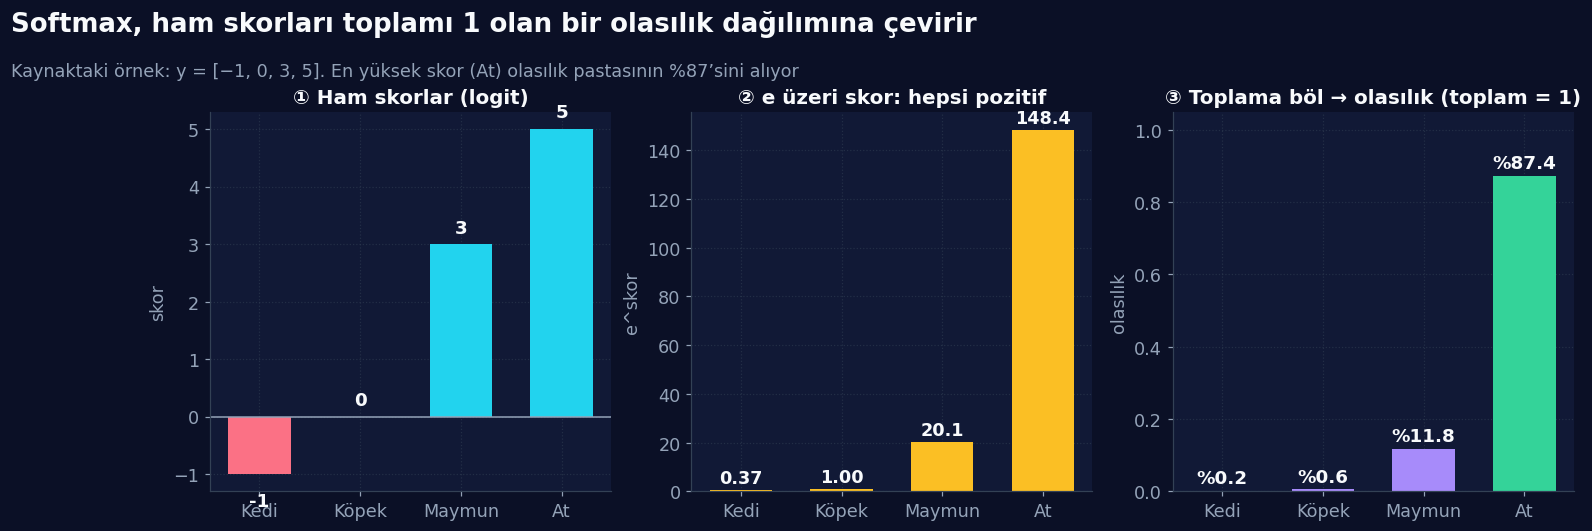

In [31]:
fig, eksenler = plt.subplots(1, 3, figsize=(16, 5.0))
renkler_sm = [RENK['mor']] * 3 + [RENK['yesil']]

ax = eksenler[0]
ax.bar(siniflar, skor, color=[RENK['gul'] if v < 0 else RENK['cam'] for v in skor], width=0.62); ax.axhline(0, color=RENK['soluk'], lw=1)
for i, v in enumerate(skor):
    ax.text(i, v + (0.2 if v >= 0 else -0.55), f'{v:g}', ha='center', color=RENK['metin'], fontsize=12, fontweight='bold')
ax.set_title('① Ham skorlar (logit)'); ax.set_ylabel('skor')

ax = eksenler[1]
ax.bar(siniflar, ustel, color=RENK['amber'], width=0.62)
for i, v in enumerate(ustel):
    ax.text(i, v + 3, f'{v:.2f}' if v < 10 else f'{v:.1f}', ha='center', color=RENK['metin'], fontsize=11.5, fontweight='bold')
ax.set_title('② e üzeri skor: hepsi pozitif'); ax.set_ylabel('e^skor')

ax = eksenler[2]
ax.bar(siniflar, olasilik, color=renkler_sm, width=0.62); ax.set_ylim(0, 1.05)
for i, v in enumerate(olasilik):
    ax.text(i, v + 0.02, f'%{v * 100:.1f}', ha='center', color=RENK['metin'], fontsize=12, fontweight='bold')
ax.set_title(f'③ Toplama böl → olasılık (toplam = {olasilik.sum():.0f})'); ax.set_ylabel('olasılık')

baslik(fig, 'Softmax, ham skorları toplamı 1 olan bir olasılık dağılımına çevirir',
       'Kaynaktaki örnek: y = [−1, 0, 3, 5]. En yüksek skor (At) olasılık pastasının %87’sini alıyor', ust=0.80)
kaydet(fig, '08_softmax')

### ❓ Neden Sigmoid Olmaz? Yan Yana Koyalım

Aynı dört ham skoru **dört ayrı sigmoid**’den geçirsek ne olur? Her sigmoid **kendi başına** 0–1 üretir; birbirlerinden **haberleri yoktur**:

Sigmoid çıktıları : [0.269 0.5   0.953 0.993]   → toplam = 2.715   ← 1 değil! olasılık dağılımı olamaz
Softmax çıktıları : [0.002 0.006 0.118 0.874]   → toplam = 1.000


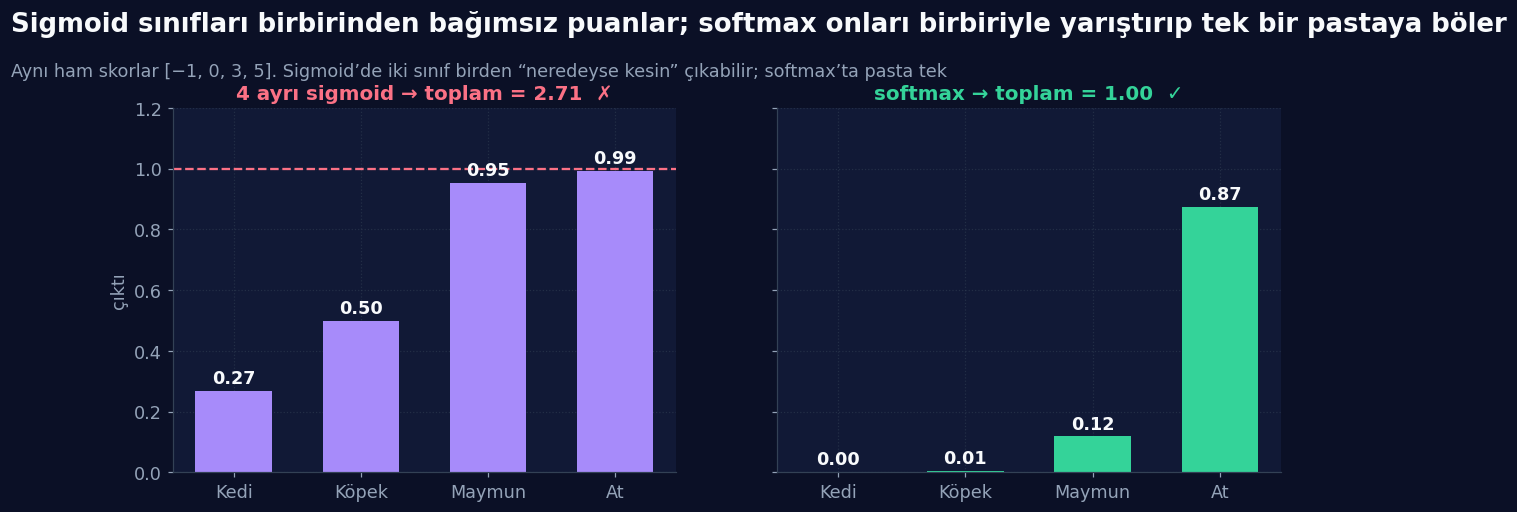

In [32]:
sig_cikti = sigmoid(skor)
print('Sigmoid çıktıları :', np.round(sig_cikti, 3), f'  → toplam = {sig_cikti.sum():.3f}   ← 1 değil! olasılık dağılımı olamaz')
print('Softmax çıktıları :', np.round(olasilik, 3), f'  → toplam = {olasilik.sum():.3f}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
ax1.bar(siniflar, sig_cikti, color=RENK['mor'], width=0.6); ax1.axhline(1, color=RENK['gul'], ls='--', lw=1.5)
for i, v in enumerate(sig_cikti):
    ax1.text(i, v + 0.025, f'{v:.2f}', ha='center', color=RENK['metin'], fontsize=11.5, fontweight='bold')
ax1.set_title(f'4 ayrı sigmoid → toplam = {sig_cikti.sum():.2f}  ✗', color=RENK['gul']); ax1.set_ylabel('çıktı'); ax1.set_ylim(0, 1.2)
ax2.bar(siniflar, olasilik, color=RENK['yesil'], width=0.6)
for i, v in enumerate(olasilik):
    ax2.text(i, v + 0.025, f'{v:.2f}', ha='center', color=RENK['metin'], fontsize=11.5, fontweight='bold')
ax2.set_title(f'softmax → toplam = {olasilik.sum():.2f}  ✓', color=RENK['yesil'])
baslik(fig, 'Sigmoid sınıfları birbirinden bağımsız puanlar; softmax onları birbiriyle yarıştırıp tek bir pastaya böler',
       'Aynı ham skorlar [−1, 0, 3, 5]. Sigmoid’de iki sınıf birden “neredeyse kesin” çıkabilir; softmax’ta pasta tek', ust=0.80)
kaydet(fig, '08_sigmoid_vs_softmax')

### 🥊 Rekabet: Biri Kazanırsa Diğerleri Kaybeder

Kaynağın söylediği: *“Bir sınıfın olasılığı artarsa diğerleri düşer.”* Bu **rekabet**, softmax’ı çok sınıflı seçim için ideal yapar. Aşağıdaki animasyonda **sadece At’ın ham skorunu** −2’den +8’e yükseltiyoruz; diğer üçünün skoru sabit (−1, 0, 3). **Diğer sınıfların olasılıklarına ne oluyor?**

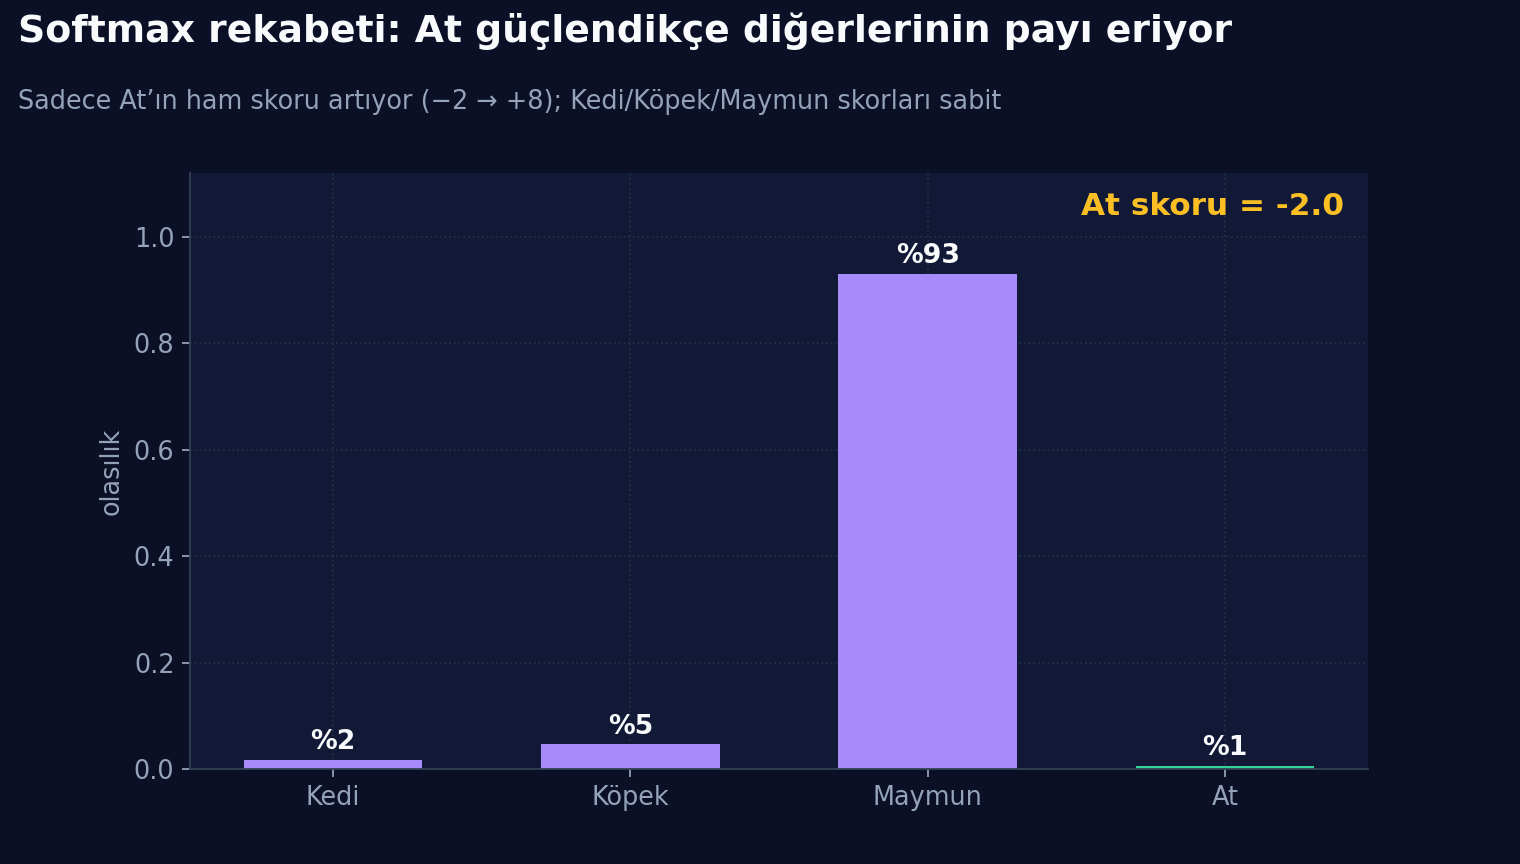

At skoru = -2  →  Kedi: % 1.7  Köpek: % 4.6  Maymun: %93.0  At: % 0.6   (toplam 1)
At skoru = +3  →  Kedi: % 0.9  Köpek: % 2.4  Maymun: %48.4  At: %48.4   (toplam 1)
At skoru = +8  →  Kedi: % 0.0  Köpek: % 0.0  Maymun: % 0.7  At: %99.3   (toplam 1)


In [33]:
def softmax_rekabet_gif(dosya, kare_sayisi=60):
    puanlar = np.linspace(-2, 8, kare_sayisi)
    sabit = np.array([-1.0, 0.0, 3.0])
    fig, ax = plt.subplots(figsize=(9.5, 5.4))
    cubuk = ax.bar(siniflar, [0.25] * 4, color=[RENK['mor']] * 3 + [RENK['yesil']], width=0.6)
    ax.set_ylim(0, 1.12); ax.set_ylabel('olasılık')
    yazilar = [ax.text(i, 0.03, '', ha='center', color=RENK['metin'], fontsize=12, fontweight='bold') for i in range(4)]
    skor_yazisi = ax.text(0.98, 0.93, '', transform=ax.transAxes, ha='right', color=RENK['amber'], fontsize=14, fontweight='bold')
    baslik(fig, 'Softmax rekabeti: At güçlendikçe diğerlerinin payı eriyor', 'Sadece At’ın ham skoru artıyor (−2 → +8); Kedi/Köpek/Maymun skorları sabit', ust=0.80)

    def kare(i):
        p = softmax(np.r_[sabit, puanlar[i]])
        for c, v, t, k in zip(cubuk, p, yazilar, range(4)):
            c.set_height(v); t.set_position((k, v + 0.02)); t.set_text(f'%{v * 100:.0f}')
        skor_yazisi.set_text(f'At skoru = {puanlar[i]:+.1f}')
        return []

    anim = FuncAnimation(fig, kare, frames=kare_sayisi, interval=80, blit=False)
    anim.save(dosya, writer=PillowWriter(fps=12))
    plt.close(fig)

GIF_YOLU = FIG_DIR / '08_softmax_rekabet.gif'
softmax_rekabet_gif(GIF_YOLU)
display(Image(filename=str(GIF_YOLU)))

for at_skoru in [-2.0, 3.0, 8.0]:
    p = softmax(np.r_[[-1.0, 0.0, 3.0], at_skoru])
    print(f'At skoru = {at_skoru:+.0f}  →  ' + '  '.join(f'{ad}: %{v * 100:4.1f}' for ad, v in zip(siniflar, p)) + f'   (toplam {p.sum():.0f})')

### 🧪 Ek Örnek (kaynakta yok): İki Küçük Deney

**1) Skorlara aynı sayıyı eklersek ne olur?** Softmax sadece skorlar **arasındaki farka** bakar:

In [34]:
a = np.array([2.0, 1.0, 0.0])
print('softmax([2, 1, 0])    =', np.round(softmax(a), 4))
print('softmax([12, 11, 10]) =', np.round(softmax(a + 10), 4), '  ← aynı sonuç: her skora +10 eklemek değiştirmedi')
assert np.allclose(softmax(a), softmax(a + 10))

# Sayısal güvenlik: skorlar çok büyükse naif formül patlar
buyuk = np.array([1000.0, 1001.0, 1002.0])
with np.errstate(all='ignore'):
    naif = np.exp(buyuk) / np.exp(buyuk).sum()
print('\nNaif formül (e^1000 taşar) :', naif, ' ← nan: hesap bozuldu')
print('Güvenli sürüm (en büyüğü çıkar):', np.round(softmax(buyuk), 4), ' ← bizim softmax() böyle yazıldı')

softmax([2, 1, 0])    = [0.6652 0.2447 0.09  ]
softmax([12, 11, 10]) = [0.6652 0.2447 0.09  ]   ← aynı sonuç: her skora +10 eklemek değiştirmedi

Naif formül (e^1000 taşar) : [nan nan nan]  ← nan: hesap bozuldu
Güvenli sürüm (en büyüğü çıkar): [0.09   0.2447 0.6652]  ← bizim softmax() böyle yazıldı


<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="icgoru">

**Neden işe yarıyor?** `e^(yᵢ − c) / Σ e^(yₖ − c)` ifadesinde `e^(−c)` hem payda hem paydada çarpan olarak var ve sadeleşir. Bu yüzden skorlardan **en büyüğünü çıkarıp** hesaplamak sonucu değiştirmez ama taşmayı önler. Gerçek kütüphanelerin hepsi böyle yapar; bizim `softmax()` fonksiyonumuz da.

</td></tr></table>

### 🧱 Softmax Neden Sadece Çıktı Katmanında Kullanılır?

Kaynağa göre sebepleri:

- Sınıflar arasında **rekabet yaratır,**
- Bir sınıfın olasılığı artarsa **diğerleri düşer,**
- **Olasılık yorumu** yapılabilir.

**Hidden layer’da bu rekabet istenmez**, çünkü özellik öğrenimi bozulur. Gizli katmandaki nöronlar birbiriyle **yarışmamalı**, *birlikte* farklı özellikleri yakalamalıdır.

🎭 **Benzetme:** Bir şirkette **müşteri temsilcileri** (gizli katman) farklı konularda uzmanlaşıp **hepsi birlikte** çalışmalı. Seçim sandığı (softmax) ise sadece **en sonda**, “nihai karar kim?” sorusu için kurulur.

### 🔗 Softmax ve Loss Fonksiyonu (Önizleme)

Softmax genellikle **Categorical Cross-Entropy** loss’u ile birlikte kullanılır. Kaynağa göre bu ikili: matematiksel olarak **uyumludur**, **gradyan hesapları stabildir** ve **modern sınıflandırma modellerinin standardıdır.** Detayını sıradaki konuda göreceğiz; ama fikir basit: gerçek sınıfa verilen olasılık `p` ise hata `−log(p)`’dir. Doğru sınıfa ne kadar yüksek olasılık verirsen, hata o kadar küçük:

In [35]:
for p_dogru in [0.99, 0.874, 0.5, 0.118, 0.01]:
    print(f'Doğru sınıfa verilen olasılık = {p_dogru:5.3f}  →  hata −log(p) = {-math.log(p_dogru):.3f}')
print('\n→ Bizim örnekte gerçek sınıf “At” olsaydı hata:', round(-math.log(olasilik[3]), 3), '(düşük: model zaten doğru yönde)')

Doğru sınıfa verilen olasılık = 0.990  →  hata −log(p) = 0.010
Doğru sınıfa verilen olasılık = 0.874  →  hata −log(p) = 0.135
Doğru sınıfa verilen olasılık = 0.500  →  hata −log(p) = 0.693
Doğru sınıfa verilen olasılık = 0.118  →  hata −log(p) = 2.137
Doğru sınıfa verilen olasılık = 0.010  →  hata −log(p) = 4.605

→ Bizim örnekte gerçek sınıf “At” olsaydı hata: 0.135 (düşük: model zaten doğru yönde)


<table><tr><td>

<img src="assets/etiket_ybs.svg" height="34" alt="ybs">

**YBS örneği, destek talebi yönlendirme:** Bir şirketin müşteri destek sistemi gelen mesajı **Fatura / Teknik / İade / Diğer** ekiplerinden birine yönlendirecek. Modelin son katmanı 4 nöronlu ve **softmax** aktivasyonlu. Ham skorlar `[0.5, 2.8, −0.3, 0.1]` ise sistem ne diyor?

</td></tr></table>

In [36]:
ekipler = ['Fatura', 'Teknik', 'İade', 'Diğer']
ham = np.array([0.5, 2.8, -0.3, 0.1])
p_ekip = softmax(ham)
display(pd.DataFrame({'Ham skor': ham, 'Olasılık': p_ekip, 'Yüzde': [f'%{v * 100:.1f}' for v in p_ekip]}, index=ekipler).round(3))
print(f'→ Mesaj “{ekipler[int(p_ekip.argmax())]}” ekibine yönlendirilir (güven: %{p_ekip.max() * 100:.0f}).')

,Ham skor,Olasılık,Yüzde
Fatura,0.5,0.083,%8.3
Teknik,2.8,0.825,%82.5
İade,-0.3,0.037,%3.7
Diğer,0.1,0.055,%5.5


→ Mesaj “Teknik” ekibine yönlendirilir (güven: %82).


<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="sonuc">

**Özet (kaynakla):** Softmax **multi-class classification** için kullanılır; **çıktıları olasılığa dönüştürür**; **output layer dışında kullanılmaz**; **cross-entropy ile birlikte çalışır.** Bir sonraki adımda: *hangi problemde hangi aktivasyon?* sorusunu net bir tabloyla bağlıyoruz.

</td></tr></table>

<a id="b9"></a>

<p align="center"><img src="assets/bolum_09.svg" width="100%" alt="Bölüm 9 — Altın Kural"></p>

### 🎭 Benzetme: Fabrikada Ara İstasyon ve Sevkiyat

Şimdiye kadar birçok aktivasyon fonksiyonu gördük: Sigmoid, Tanh, ReLU, Leaky ReLU / PReLU, GELU, Softmax. Gerçek bir model kurarken akla gelen soru: **“Tamam ama hangisini nerede kullanacağım?”**

Bir **fabrikayı** düşün. Ürün önce **ara istasyonlardan** (gizli katmanlar) geçer: burada işçiler **hızlı ve verimli** çalışmalı, ham maddeden **karmaşık parçalar** üretmeli. En sonda **sevkiyat** (çıktı katmanı) var: burada iş, ürünü **müşterinin anlayacağı biçimde** paketlemek (“bu mu, şu mu, % kaç?”).

Bir sinir ağında da iki kritik yer vardır, ve **bu iki katmanın aktivasyon amaçları farklıdır:**

- 🧱 **Hidden Layers (özellik öğrenme):** Veriden karmaşık örüntüler öğrenmek, doğrusal olmayan ilişkileri yakalamak. İstemediklerimiz: **vanishing gradient, yavaş öğrenme, gereksiz hesaplama maliyeti.**
- 🎯 **Output Layer (karar verme):** Nihai kararı üretmek ve model çıktısını **yorumlanabilir** hâle getirmek. Burada **problem türü belirleyicidir.**

<p align="center"><img src="assets/karar_agaci.svg" width="100%" alt="Animasyon: karar ağacı, hangi katmanda hangi aktivasyon"></p>

### 🏅 Altın Kural (Ezberlenecek Kısım)

| Katman | Problem Türü | Aktivasyon |
|:--|:--|:--|
| **Hidden Layer** | Her türlü | **ReLU** / Leaky ReLU / GELU |
| **Output Layer** | Binary Classification | **Sigmoid** |
| **Output Layer** | Multi-Class Classification | **Softmax** |

**Gizli katman için öneriler (kaynak):**

- ✅ **Varsayılan ve güvenli seçim: ReLU**
- 🔧 ReLU ile sorun yaşıyorsan (ölü nöron): **Leaky ReLU / Parametric ReLU**
- 🚀 Modern ve ileri seviye modeller (özellikle **Transformer**): **GELU**

Özetle: **Hidden layer = ReLU veya türevleri.** Derin ağlarda **sigmoid ve tanh hidden layer için önerilmez**, çünkü türevleri sınırlıdır, derin ağlarda gradyan küçülür ve vanishing gradient problemi çıkar.

**Çıktı katmanı için:** Binary (spam / değil, hasta / sağlıklı) → **tek nöron, aralık [0, 1], Sigmoid.** Multi-class (kedi / köpek / at / kuş) → **birden fazla nöron, olasılıkların toplamı = 1, Softmax.**

> 💡 **Kararsızsan:** Hidden layer: **ReLU** · Binary output: **Sigmoid** · Multi-class output: **Softmax.** Bu kombinasyon çoğu problem için yeterlidir ve **endüstri standardıdır.**

<table><tr><td>

<img src="assets/etiket_not.svg" height="34" alt="not">

**Ek bilgi (kaynakta yok):** Çıktısı **bir sayı** olan problemlerde (örneğin “gelecek ay satış kaç adet olacak?”, yani regresyon) çıktı katmanında genellikle **aktivasyon kullanılmaz** (düz doğrusal çıktı). Bunu ileride göreceğiz; bugünkü altın kural **sınıflandırma** içindir.

</td></tr></table>

### 🧰 Altın Kuralı Koda Dökelim

Kuralı bir fonksiyona çevirelim: katman türünü ve (çıktı katmanıysa) sınıf sayısını verince **önerilen aktivasyonu** ve **çıktı nöron sayısını** söylesin:

In [37]:
def onerilen_aktivasyon(katman, sinif_sayisi=None):
    """Altın kural: gizli katmanda ReLU ailesi/GELU; çıktıda binary → sigmoid, multi-class → softmax."""
    if katman == 'gizli':
        return {'aktivasyon': 'ReLU (sorun varsa Leaky/PReLU; Transformer ise GELU)', 'nöron sayısı': 'serbest (mimariye bağlı)'}
    if katman == 'çıktı':
        if sinif_sayisi == 2:
            return {'aktivasyon': 'Sigmoid', 'nöron sayısı': 1}
        if sinif_sayisi and sinif_sayisi > 2:
            return {'aktivasyon': 'Softmax', 'nöron sayısı': sinif_sayisi}
    raise ValueError('Katman “gizli” ya da “çıktı” olmalı; çıktı için sınıf sayısı ≥ 2 verilmeli.')

senaryolar = [('Ağın ortadaki katmanları', 'gizli', None), ('Spam filtresi (spam / değil)', 'çıktı', 2), ('Kredi onayı (onay / ret)', 'çıktı', 2),
              ('Hayvan tanıma (kedi/köpek/maymun/at)', 'çıktı', 4), ('Destek talebi yönlendirme (4 ekip)', 'çıktı', 4), ('Müşteri segmenti (5 segment)', 'çıktı', 5)]
satirlar = []
for ad, katman, k in senaryolar:
    o = onerilen_aktivasyon(katman, k)
    satirlar.append({'Senaryo': ad, 'Katman': katman, 'Sınıf sayısı': k if k else '-', 'Önerilen aktivasyon': o['aktivasyon'], 'Çıktı nöronu': o['nöron sayısı']})
display(pd.DataFrame(satirlar).set_index('Senaryo'))

,Katman,Sınıf sayısı,Önerilen aktivasyon,Çıktı nöronu
Senaryo,,,,
Ağın ortadaki katmanları,gizli,-,ReLU (sorun varsa Leaky/PReLU; Transformer ise...,serbest (mimariye bağlı)
Spam filtresi (spam / değil),çıktı,2,Sigmoid,1
Kredi onayı (onay / ret),çıktı,2,Sigmoid,1
Hayvan tanıma (kedi/köpek/maymun/at),çıktı,4,Softmax,4
Destek talebi yönlendirme (4 ekip),çıktı,4,Softmax,4
Müşteri segmenti (5 segment),çıktı,5,Softmax,5


### ❌ En Sık Yapılan Üç Hata (ve Neden Hata?)

Kaynağa göre en sık yapılan hatalar:

1. **Hidden layer’da sigmoid kullanmak,**
2. **Output layer’da ReLU kullanmak,**
3. **Multi-class problemde sigmoid kullanmak.**

Bu hatalar **öğrenmeyi yavaşlatır** ve **yanlış olasılık yorumlarına** yol açar. Üçünü de somut gösterelim:

In [38]:
print('HATA 2: Binary problemde çıktı katmanında ReLU')
for z_ in [3.7, -1.2]:
    print(f'  z = {z_:+.1f}  →  ReLU = {float(relu(z_)):.1f}   |   sigmoid = {float(sigmoid(z_)):.3f}')
print('  → ReLU “olasılık” diye 3.7 verir (%370?), negatifte ise tam 0 (“kesin hayır”) der. Olasılık yorumu çöker.\n')

print('HATA 3: 4 sınıflı problemde sigmoid')
print(f'  sigmoid çıktıları toplamı = {sigmoid(skor).sum():.2f} ≠ 1  → olasılık dağılımı değil (Bölüm 8)\n')

print('HATA 1: Gizli katmanda sigmoid → en iyi durumda bile her katmanda ×0.25')
print(f'  8 gizli katmandan sonra sinyalin en fazla {0.25 ** 8:.1e} kadarı kalır (Bölüm 3). Bunu Bölüm 10’da eğitimle kanıtlıyoruz.')

HATA 2: Binary problemde çıktı katmanında ReLU
  z = +3.7  →  ReLU = 3.7   |   sigmoid = 0.976
  z = -1.2  →  ReLU = 0.0   |   sigmoid = 0.231
  → ReLU “olasılık” diye 3.7 verir (%370?), negatifte ise tam 0 (“kesin hayır”) der. Olasılık yorumu çöker.

HATA 3: 4 sınıflı problemde sigmoid
  sigmoid çıktıları toplamı = 2.71 ≠ 1  → olasılık dağılımı değil (Bölüm 8)

HATA 1: Gizli katmanda sigmoid → en iyi durumda bile her katmanda ×0.25
  8 gizli katmandan sonra sinyalin en fazla 1.5e-05 kadarı kalır (Bölüm 3). Bunu Bölüm 10’da eğitimle kanıtlıyoruz.


<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="sonuc">

**Kapanış cümlesi (kaynaktan):** *“Hangi aktivasyonu kullandığın, en az model mimarisi kadar önemlidir.”* Aktivasyon fonksiyonları **modelin öğrenme şeklini belirler**; yanlış seçim, doğru modeli bile bozabilir. Şimdi bu iddiayı **ölçerek** sınayalım.

</td></tr></table>

<a id="b10"></a>

<p align="center"><img src="assets/bolum_10.svg" width="100%" alt="Bölüm 10 — Aktivasyon Arenası"></p>

### 🥊 Aktivasyon Arenası: Hepsi Aynı Ringde

Bugüne kadar söylenenleri **kendi deneyimizle** sınayalım. Üç sınav var:

1. 🧬 **Gradyan sınavı:** 10 katmanlı bir ağda gradyan, çıktıdan girdiye doğru **ne kadar yol kat ediyor?**
2. 🏋️ **Eğitim sınavı:** Aynı veri, aynı ağ, **sadece aktivasyon farklı.** Hangisi öğrenebiliyor?
3. ⏱️ **Hız sınavı:** Hangisi daha ucuza hesaplanıyor?

Yarışmacılar: **Sigmoid, Tanh, ReLU, Leaky ReLU (α = 0.01), GELU.** Her aktivasyonu **hakkıyla** başlatıyoruz: sigmoid/tanh için **Xavier**, ReLU ailesi ve GELU için **He** başlatma (Gün 1’de gördüğümüz “akıllı başlangıç”). Böylece kimseye haksızlık etmiyoruz.

### 🧬 Sınav 1: Gradyan Katmanlardan Nasıl Geçiyor?

Gün 1’deki deneyin genişletilmişi: 10 gizli katmanlı (katman başına 16 nöron) bir ağda geri yayılımı elle yazıp **her katmandaki ortalama gradyan büyüklüğünü** ölçüyoruz (20 farklı rastgele başlangıcın ortalaması). **Katman 1 = girdiye en yakın, katman 10 = çıktıya en yakın.**

In [39]:
AKTIVASYONLAR = {
    'Sigmoid':    (sigmoid, sigmoid_turev, 'xavier', RENK['mor']),
    'Tanh':       (tanh, tanh_turev, 'xavier', RENK['cam']),
    'ReLU':       (relu, relu_turev, 'he', RENK['yesil']),
    'Leaky ReLU': (lambda z: leaky_relu(z, 0.01), lambda z: leaky_relu_turev(z, 0.01), 'he', '#86EFAC'),
    'GELU':       (gelu, gelu_turev, 'he', RENK['amber']),
}

def derin_ag_gradyanlari(ad, derinlik=10, genislik=16, tohum=0):
    """Derin bir ağda her katmanın ağırlık gradyanının ortalama büyüklüğü (|∂L/∂W|)."""
    f, df, baslatma, _ = AKTIVASYONLAR[ad]
    rng = np.random.default_rng(tohum)
    X_ = rng.normal(size=(64, genislik)); Y_ = rng.normal(size=(64, 1))
    olcek = np.sqrt(2 / genislik) if baslatma == 'he' else np.sqrt(1 / genislik)
    Ws = [rng.normal(0, olcek, size=(genislik, genislik)) for _ in range(derinlik)]
    W_cikis = rng.normal(0, olcek, size=(genislik, 1))
    A, Z = [X_], []
    for W in Ws:                                    # ileri geçiş
        Z.append(A[-1] @ W); A.append(f(Z[-1]))
    cikis = A[-1] @ W_cikis
    dA = (2 * (cikis - Y_) / len(Y_)) @ W_cikis.T   # çıktıdan geriye ilk adım
    normlar = np.zeros(derinlik)
    for i in reversed(range(derinlik)):             # geri yayılım: sondan başa
        dZ = dA * df(Z[i])
        normlar[i] = np.mean(np.abs(A[i].T @ dZ))
        dA = dZ @ Ws[i].T
    return normlar

N_TOHUM = 20
grad = {ad: np.mean([derin_ag_gradyanlari(ad, tohum=s) for s in range(N_TOHUM)], axis=0) for ad in AKTIVASYONLAR}

print('Katman:        ' + ' '.join(f'{i:>8}' for i in range(1, 11)))
for ad, g in grad.items():
    print(f'{ad:<13}: ' + ' '.join(f'{v:8.1e}' for v in g))
print()
oran = pd.Series({ad: g[0] / g[-1] for ad, g in grad.items()}, name='1. katman gradyanı / 10. katman gradyanı')
display(oran.to_frame().map(lambda v: f'{v:.1e}'))
# Anlatımımızı doğruluyoruz
assert oran['Sigmoid'] < 1e-4 and all(oran[a] > 0.1 for a in ['Tanh', 'ReLU', 'Leaky ReLU', 'GELU'])

Katman:               1        2        3        4        5        6        7        8        9       10
Sigmoid      :  2.3e-08  2.2e-07  9.1e-07  3.7e-06  1.6e-05  6.1e-05  2.6e-04  1.1e-03  5.2e-03  2.3e-02
Tanh         :  1.3e-02  1.1e-02  1.1e-02  1.2e-02  1.2e-02  1.1e-02  1.1e-02  1.2e-02  1.3e-02  1.5e-02
ReLU         :  1.3e-01  1.8e-01  2.0e-01  1.9e-01  1.8e-01  1.7e-01  1.8e-01  1.7e-01  1.9e-01  2.0e-01
Leaky ReLU   :  1.3e-01  1.9e-01  2.0e-01  1.9e-01  1.9e-01  1.8e-01  1.8e-01  1.8e-01  2.0e-01  2.0e-01
GELU         :  1.0e-01  1.2e-01  1.2e-01  1.2e-01  1.0e-01  9.9e-02  9.2e-02  8.0e-02  8.9e-02  8.7e-02



,1. katman gradyanı / 10. katman gradyanı
Sigmoid,1.0e-06
Tanh,8.5e-01
ReLU,6.4e-01
Leaky ReLU,6.3e-01
GELU,1.2e+00


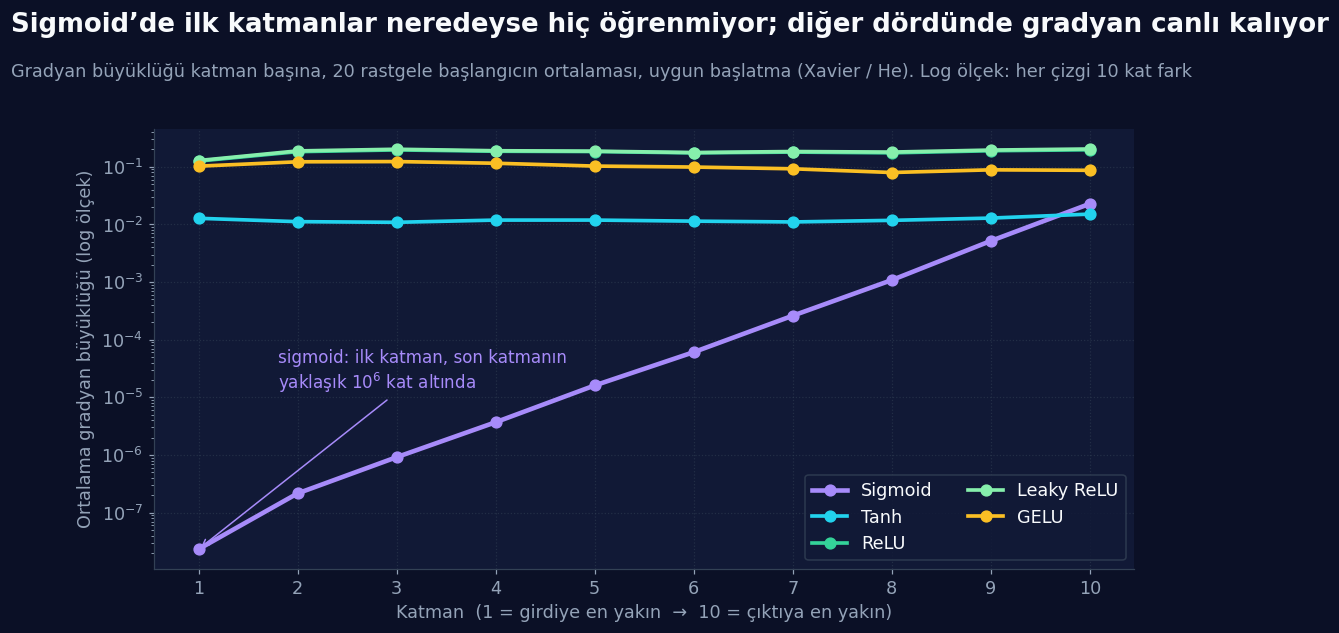

In [40]:
katmanlar = np.arange(1, 11)
fig, ax = plt.subplots(figsize=(11.5, 5.8))
for ad, g in grad.items():
    renk = AKTIVASYONLAR[ad][3]
    ax.plot(katmanlar, g, '-o', color=renk, lw=3.0 if ad == 'Sigmoid' else 2.4, ms=7, label=ad)
ax.set_yscale('log'); ax.set_xticks(katmanlar)
ax.set_xlabel('Katman  (1 = girdiye en yakın  →  10 = çıktıya en yakın)'); ax.set_ylabel('Ortalama gradyan büyüklüğü (log ölçek)')
ax.annotate(f'sigmoid: ilk katman, son katmanın\nyaklaşık $10^{{{int(round(np.log10(grad["Sigmoid"][-1] / grad["Sigmoid"][0])))}}}$ kat altında', (1, grad['Sigmoid'][0]),
            xytext=(1.8, grad['Sigmoid'][0] * 600), color=RENK['mor'], fontsize=11, arrowprops=dict(arrowstyle='->', color=RENK['mor']))
ax.legend(loc='lower right', ncol=2)
baslik(fig, 'Sigmoid’de ilk katmanlar neredeyse hiç öğrenmiyor; diğer dördünde gradyan canlı kalıyor',
       'Gradyan büyüklüğü katman başına, 20 rastgele başlangıcın ortalaması, uygun başlatma (Xavier / He). Log ölçek: her çizgi 10 kat fark', ust=0.80)
kaydet(fig, '10_gradyan_katman')

<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="dikkat">

**Dürüst gözlem:** Bu oyuncak ağda **tanh**, Xavier başlatmayla **10 katman boyunca sağlıklı bir gradyan** taşıdı. Kaynağın söylediği “tanh vanishing gradient’i azaltır ama tamamen kaldırmaz” cümlesiyle çelişmez: tanh’ın türevi 1’e kadar çıkabildiği için **iyi başlatılmış, orta derinlikte** bir ağda sorun çıkarmaz; sorun, nöronlar **doyduğunda** (|z| büyüdüğünde, Bölüm 4’teki tabloya bak) ve ağ **çok daha derinleştiğinde** ortaya çıkar. **Sigmoid** ise en iyi başlatmayla bile **en iyi durumda 0.25 ile çarpıldığı** için ilk katmanlarda milyonda bire düşüyor. Sayılar mimariye göre değişir; **eğilim** değişmez.

</td></tr></table>

### 🏋️ Sınav 2: Aynı Ağ, Aynı Veri, Sadece Aktivasyon Farklı

Veri olarak elde üretilen **“iki ay” (two moons)** problemini kullanıyoruz: iki birbirine geçmiş yarım daire, **doğrusal olarak ayrılamayan** klasik bir ikili sınıflandırma örneği (simülasyon verisi, 300 nokta). Ağ: `2 girdi → [16 nöronluk N gizli katman] → 1 çıktı (sigmoid)`; hata olarak **ikili çapraz entropi** (binary cross-entropy; ayrıntısı sıradaki konularda), eğitim **düz gradient descent** (öğrenme oranı 0.1, 1000 adım). İki ağ derinliği deneyeceğiz: **N = 2 (sığ)** ve **N = 8 (derin).**

Çıktı katmanı **sigmoid** olduğu için altın kurala uyuyoruz (binary classification); **yalnızca gizli katman aktivasyonu** değişiyor.

In [41]:
def iki_ay(n=300, gurultu=0.12, tohum=0):
    """El yapımı 'two moons' veri seti (simülasyon)."""
    r = np.random.default_rng(tohum)
    t = r.uniform(0, math.pi, n // 2)
    ust = np.c_[np.cos(t), np.sin(t)]
    alt = np.c_[1 - np.cos(t), 0.5 - np.sin(t)]
    X_ = np.r_[ust, alt] + r.normal(0, gurultu, (n, 2))
    y_ = np.r_[np.zeros(n // 2), np.ones(n // 2)]
    return X_, y_

def mlp_egit(ad, X_, y_, derinlik=8, genislik=16, lr=0.1, epoch=1000, tohum=0):
    """Gizli katman aktivasyonu 'ad' olan MLP; çıktı sigmoid + BCE. Geri yayılım elle yazıldı."""
    f, df, baslatma, _ = AKTIVASYONLAR[ad]
    r = np.random.default_rng(tohum)
    boy = [X_.shape[1]] + [genislik] * derinlik + [1]
    Ws, bs = [], []
    for i in range(len(boy) - 1):
        olcek = np.sqrt(2 / boy[i]) if baslatma == 'he' else np.sqrt(1 / boy[i])
        Ws.append(r.normal(0, olcek, (boy[i], boy[i + 1]))); bs.append(np.zeros(boy[i + 1]))
    kayip_, dogruluk_ = [], []
    for _ in range(epoch):
        A, Z = [X_], []
        for i in range(derinlik):
            Z.append(A[-1] @ Ws[i] + bs[i]); A.append(f(Z[-1]))
        p = sigmoid(A[-1] @ Ws[-1] + bs[-1])[:, 0]
        kayip_.append(-(y_ * np.log(p + 1e-12) + (1 - y_) * np.log(1 - p + 1e-12)).mean())
        dogruluk_.append(((p > 0.5) == y_).mean())
        dz = ((p - y_) / len(y_))[:, None]                 # sigmoid + BCE birleşince türev (p − y)
        gW, gb = [None] * len(Ws), [None] * len(Ws)
        gW[-1] = A[-1].T @ dz; gb[-1] = dz.sum(0); dA = dz @ Ws[-1].T
        for i in reversed(range(derinlik)):
            dZ = dA * df(Z[i]); gW[i] = A[i].T @ dZ; gb[i] = dZ.sum(0); dA = dZ @ Ws[i].T
        for i in range(len(Ws)):
            Ws[i] -= lr * gW[i]; bs[i] -= lr * gb[i]

    def tahmin(Xg):
        a = Xg
        for i in range(derinlik):
            a = f(a @ Ws[i] + bs[i])
        return sigmoid(a @ Ws[-1] + bs[-1])[:, 0]
    return np.array(kayip_), np.array(dogruluk_), tahmin

X_ay, y_ay = iki_ay()
print(f'Veri: {len(y_ay)} nokta, sınıf dağılımı = {int((y_ay == 0).sum())} / {int((y_ay == 1).sum())} (simülasyon)')

Veri: 300 nokta, sınıf dağılımı = 150 / 150 (simülasyon)


In [42]:
t0 = time.perf_counter()
SONUC = {derinlik: {ad: mlp_egit(ad, X_ay, y_ay, derinlik=derinlik) for ad in AKTIVASYONLAR} for derinlik in (2, 8)}
print(f'Toplam eğitim süresi: {time.perf_counter() - t0:.1f} sn\n')

satir = {}
for ad in AKTIVASYONLAR:
    satir[ad] = {}
    for d in (2, 8):
        satir[ad][(f'N = {d} gizli katman', 'Son kayıp')] = SONUC[d][ad][0][-1]
        satir[ad][(f'N = {d} gizli katman', 'Doğruluk')] = SONUC[d][ad][1][-1]
tablo_arena = pd.DataFrame.from_dict(satir, orient='index')
tablo_arena.columns = pd.MultiIndex.from_tuples(tablo_arena.columns)
display(tablo_arena.round(3))

# Anlatımımızı doğruluyoruz: derin ağda sigmoid öğrenemiyor (kayıp ≈ ln2 = 0.693), diğerleri öğreniyor
assert SONUC[8]['Sigmoid'][0][-1] > 0.6 and all(SONUC[8][a][0][-1] < 0.05 for a in ['Tanh', 'ReLU', 'Leaky ReLU', 'GELU'])
print(f'ln 2 = {math.log(2):.3f}  ← “hiçbir şey öğrenemedim, yazı tura atıyorum” anındaki kayıp')

Toplam eğitim süresi: 5.0 sn



N = 2 gizli katman          N = 8 gizli katman         
                    Son kayıp Doğruluk          Son kayıp Doğruluk
Sigmoid                 0.301    0.860              0.693    0.703
Tanh                    0.032    0.997              0.001    1.000
ReLU                    0.010    1.000              0.000    1.000
Leaky ReLU              0.010    1.000              0.000    1.000
GELU                    0.011    1.000              0.000    1.000

ln 2 = 0.693  ← “hiçbir şey öğrenemedim, yazı tura atıyorum” anındaki kayıp


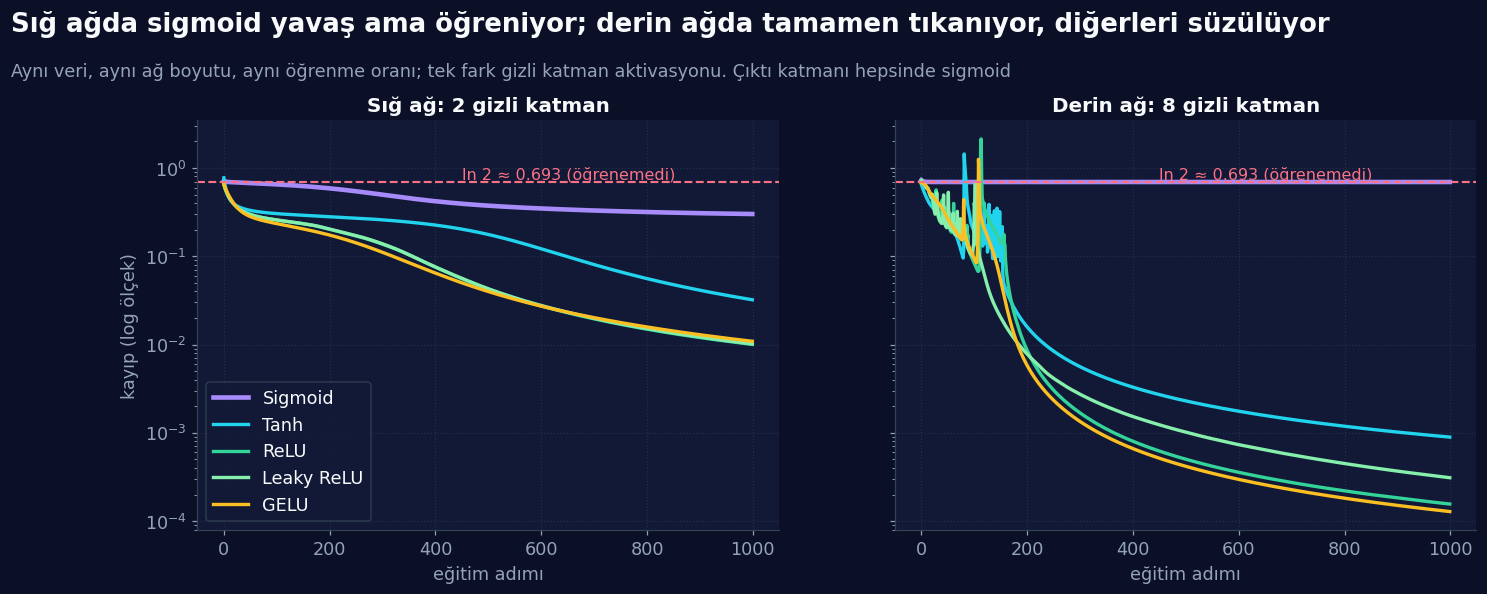

In [43]:
fig, eksenler = plt.subplots(1, 2, figsize=(15, 5.4), sharey=True)
for ax, derinlik, ad_ in zip(eksenler, (2, 8), ('Sığ ağ: 2 gizli katman', 'Derin ağ: 8 gizli katman')):
    for ad in AKTIVASYONLAR:
        ax.plot(SONUC[derinlik][ad][0], color=AKTIVASYONLAR[ad][3], lw=3.0 if ad == 'Sigmoid' else 2.2, label=ad)
    ax.axhline(math.log(2), color=RENK['gul'], ls='--', lw=1.4); ax.text(450, math.log(2) * 1.07, 'ln 2 ≈ 0.693 (öğrenemedi)', color=RENK['gul'], fontsize=10.5)
    ax.set_yscale('log'); ax.set_xlabel('eğitim adımı'); ax.set_title(ad_)
eksenler[0].set_ylabel('kayıp (log ölçek)'); eksenler[0].legend(loc='lower left')
baslik(fig, 'Sığ ağda sigmoid yavaş ama öğreniyor; derin ağda tamamen tıkanıyor, diğerleri süzülüyor',
       'Aynı veri, aynı ağ boyutu, aynı öğrenme oranı; tek fark gizli katman aktivasyonu. Çıktı katmanı hepsinde sigmoid', ust=0.80)
kaydet(fig, '10_arena_kayip')

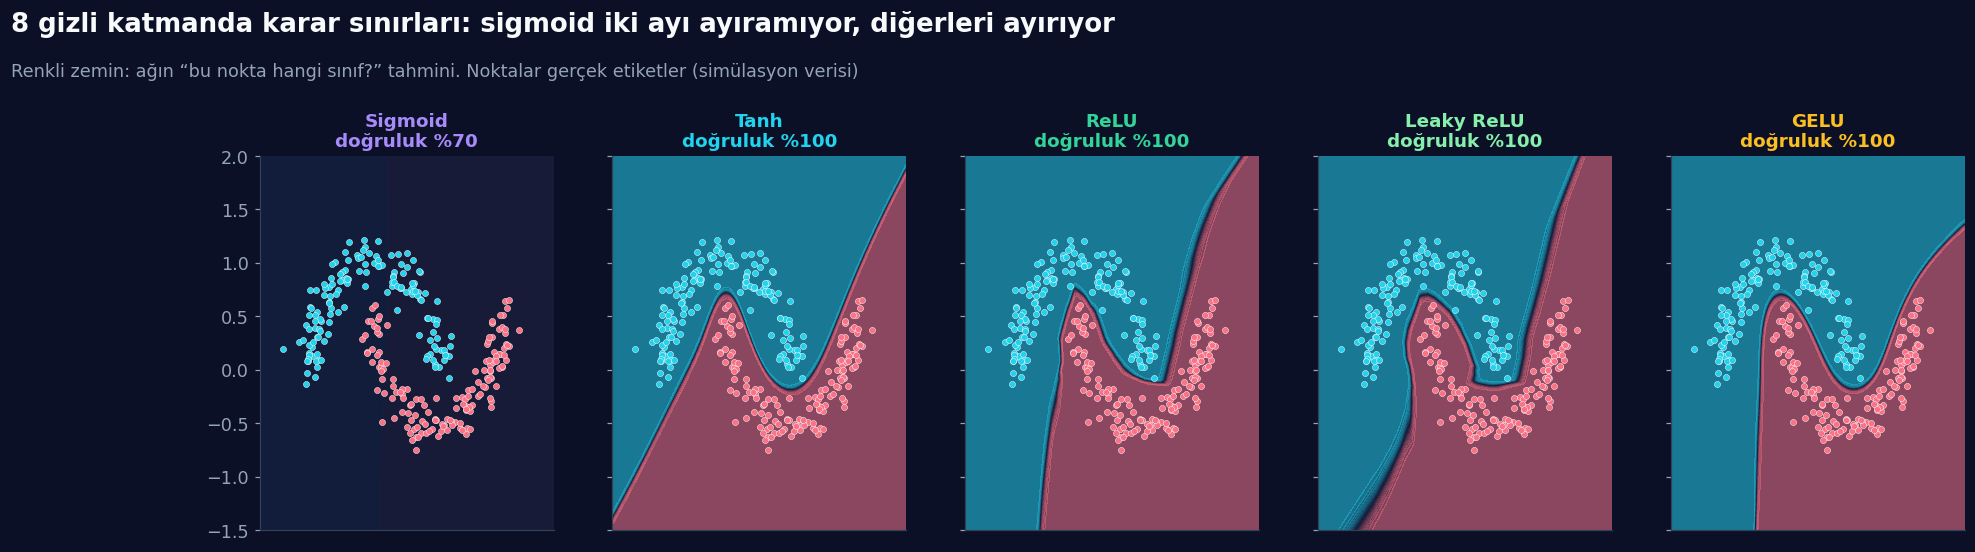

In [44]:
xx, yy = np.meshgrid(np.linspace(-1.8, 2.8, 220), np.linspace(-1.5, 2.0, 220))
izgara = np.c_[xx.ravel(), yy.ravel()]
fig, eksenler = plt.subplots(1, 5, figsize=(20, 5.4), sharey=True)
for ax, ad in zip(eksenler, AKTIVASYONLAR):
    kayip_, dogruluk_, tahmin = SONUC[8][ad]
    zemin = tahmin(izgara).reshape(xx.shape)
    ax.contourf(xx, yy, zemin, levels=np.linspace(0, 1, 21), cmap=mpl.colors.LinearSegmentedColormap.from_list('sinir', [RENK['cam'], RENK['panel'], RENK['gul']]), alpha=0.55)
    ax.scatter(X_ay[y_ay == 0, 0], X_ay[y_ay == 0, 1], s=16, color=RENK['cam'], edgecolor='white', linewidth=0.3)
    ax.scatter(X_ay[y_ay == 1, 0], X_ay[y_ay == 1, 1], s=16, color=RENK['gul'], edgecolor='white', linewidth=0.3)
    ax.set_title(f'{ad}\ndoğruluk %{dogruluk_[-1] * 100:.0f}', color=AKTIVASYONLAR[ad][3], fontsize=12); ax.set_xticks([]); ax.grid(False)
baslik(fig, '8 gizli katmanda karar sınırları: sigmoid iki ayı ayıramıyor, diğerleri ayırıyor',
       'Renkli zemin: ağın “bu nokta hangi sınıf?” tahmini. Noktalar gerçek etiketler (simülasyon verisi)', ust=0.74)
kaydet(fig, '10_arena_sinirlar')

<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="sonuc">

**Bu çalıştırmadaki sonuç:** **8 gizli katmanlı** ağda **sigmoid** kaybı `ln 2 ≈ 0.693` civarında takılı kaldı, yani **hiçbir şey öğrenemedi** (karar sınırı neredeyse düz); **tanh, ReLU, Leaky ReLU ve GELU** ise veriyi neredeyse kusursuz ayırdı. **2 katmanlı** sığ ağda sigmoid **öğrenebiliyor** ama diğerlerinden **belirgin biçimde yavaş ve kötü.** Altın kuralın “derin ağda gizli katmanda sigmoid kullanma” uyarısının **deneyle kanıtı** budur.

*Dürüstlük notu:* Bu tek bir veri seti, tek bir mimari ve tek bir rastgele başlangıç (`tohum = 0`); **kesin bir sıralama** değil, **eğilim** gösteriyor. Tanh, ReLU, Leaky ReLU ve GELU arasındaki farklar bu küçük problemde çok küçük; onları ayırmak için daha büyük problemler gerekir.

</td></tr></table>

### ⏱️ Sınav 3: Hız

Kaynak, ReLU için **“hesaplama olarak çok hızlıdır”**, GELU için ise **“kısmen yavaş”** diyordu. **5 milyon sayılık** bir diziyi her aktivasyondan geçirip süreyi ölçelim (her biri için 5 denemenin en iyisi):

,Süre (ms),ReLU’ya göre kat
ReLU,9.2,1.0
Leaky ReLU,25.7,2.8
Tanh,35.1,3.8
Sigmoid,45.6,4.9
GELU,161.2,17.5


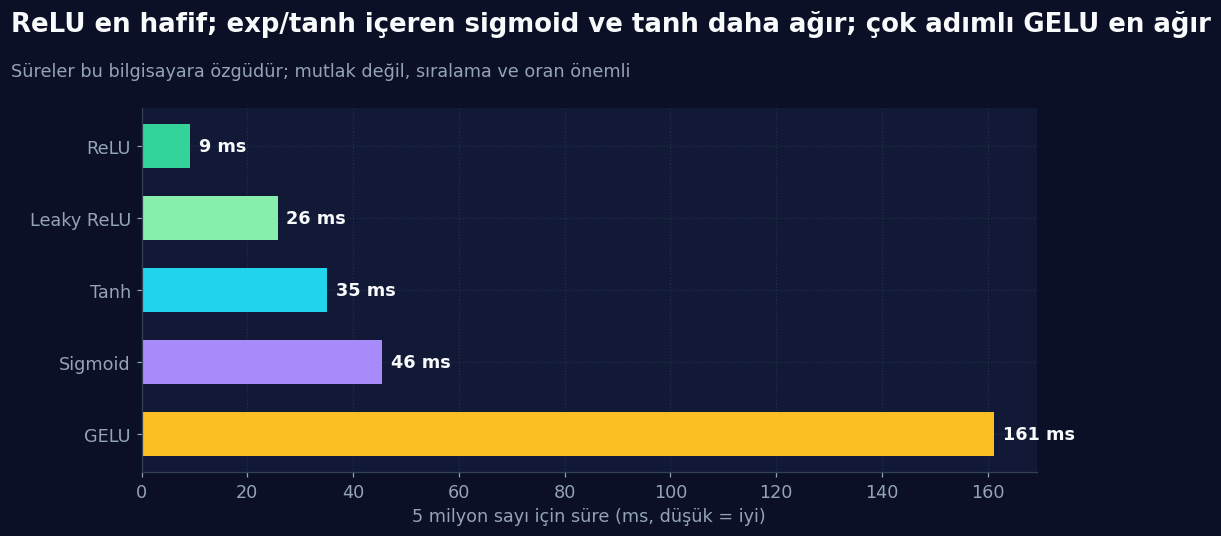

In [45]:
v = np.random.default_rng(0).normal(size=5_000_000)
hizlar = {}
for ad in AKTIVASYONLAR:
    f = AKTIVASYONLAR[ad][0]
    f(v[:1000])                                                   # ısınma
    sureler = []
    for _ in range(5):
        t0 = time.perf_counter(); f(v); sureler.append(time.perf_counter() - t0)
    hizlar[ad] = min(sureler) * 1000

hiz_tablo = pd.DataFrame({'Süre (ms)': hizlar})
hiz_tablo['ReLU’ya göre kat'] = hiz_tablo['Süre (ms)'] / hizlar['ReLU']
display(hiz_tablo.sort_values('Süre (ms)').round(1))

fig, ax = plt.subplots(figsize=(10.5, 4.8))
sirali = sorted(hizlar, key=hizlar.get)
ax.barh(sirali, [hizlar[a] for a in sirali], color=[AKTIVASYONLAR[a][3] for a in sirali], height=0.6)
for i, a in enumerate(sirali):
    ax.text(hizlar[a] + max(hizlar.values()) * 0.01, i, f'{hizlar[a]:.0f} ms', va='center', color=RENK['metin'], fontsize=11.5, fontweight='bold')
ax.invert_yaxis(); ax.set_xlabel('5 milyon sayı için süre (ms, düşük = iyi)')
baslik(fig, 'ReLU en hafif; exp/tanh içeren sigmoid ve tanh daha ağır; çok adımlı GELU en ağır', 'Süreler bu bilgisayara özgüdür; mutlak değil, sıralama ve oran önemli', ust=0.80)
kaydet(fig, '10_hiz_testi')

<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="dikkat">

**Not:** Süreler **bu bilgisayara ve NumPy sürümüne** göre değişir; tabloyu mutlak değil **oran** olarak oku. (Leaky ReLU burada `np.where` kullandığı için ReLU’dan birkaç kat yavaş görünüyor; optimize edilmiş kütüphanelerde ikisi de “çok hızlı” sınıfındadır.) Gerçek derin öğrenme kütüphaneleri (GPU’da, özel çekirdeklerle) bu fonksiyonları çok daha hızlı hesaplar; ama **üstel işlem içeren fonksiyonların basit karşılaştırmalara göre daha pahalı olduğu** genel gerçeği geçerlidir.

</td></tr></table>

<a id="b11"></a>

<p align="center"><img src="assets/bolum_11.svg" width="100%" alt="Bölüm 11 — Kapanış"></p>

### 📚 Büyük Özet: Üç Perde, Tek Hikâye

| Perde | Kavram | Tek cümlelik özet | Günlük hayat benzetmesi |
|:--|:--|:--|:--|
| **1. Klasikler** | Sigmoid | `σ(z) = 1/(1+e⁻ᶻ)`, çıktı **(0, 1)**; binary çıktı için uygun | Dimmer |
| | Sigmoid’in 3 derdi | Türev ≤ 0.25 (kaybolan gradyan) · 0 merkezli değil · üstel işlem | Fısıltı oyunu · tek yönlü defter · ağır hesap makinesi |
| | Tanh | Çıktı **(−1, +1)**, zero-centered, türev ≤ 1; derinlikte yine yetmez | İbresi ortada terazi |
| **2. Modern gizli katman** | ReLU | `max(0, x)`: hızlı, pozitifte türev 1; **ölü nöron** riski | Tek yönlü turnike |
| | Dead neuron | Sürekli negatif → çıktı 0, türev 0, güncelleme yok | Bir kez kapanıp açılmayan şalter |
| | Leaky ReLU / PReLU | Negatifte `α·x`; α sabit (Leaky) ya da öğrenilir (PReLU) | Yangın kapısının altındaki aralık |
| | GELU | `x · Φ(x)`: olasılıksal, pürüzsüz; Transformer standardı | Olasılıkla geçiren kapıcı |
| **3. Çıktı katmanı** | Softmax | Ham skorları toplamı 1 olan olasılığa çevirir; çok sınıflı çıktı | Seçim sandığı |
| | Altın kural | Gizli: **ReLU ailesi / GELU** · Binary çıktı: **Sigmoid** · Multi-class çıktı: **Softmax** | Ara istasyon ↔ sevkiyat |

### 🃏 Flashcard Izgarası (Cevabı kapat, kendin söyle!)

<table><tr>
<td width="33%" valign="top"><b>❓ Aktivasyon fonksiyonu neden gerekli?</b><br><br>👉 Ham skoru anlamlı bir aralığa/karara çevirir ve ağa doğrusal olmayanlık (karmaşık şekilleri öğrenme gücü) katar.</td>
<td width="33%" valign="top"><b>❓ Sigmoid türevi en fazla kaç olabilir?</b><br><br>👉 0.25 (z = 0’da). Bu yüzden derin ağlarda gradyan katman katman çeyreğe iner.</td>
<td width="33%" valign="top"><b>❓ Zero-centered ne demek, kim öyle?</b><br><br>👉 Çıktı ortalamasının ≈ 0 olması. Tanh öyle, sigmoid değil.</td>
</tr><tr>
<td width="33%" valign="top"><b>❓ Ölü nöron nedir?</b><br><br>👉 Sürekli negatif girdi alan ReLU nöronu: çıktı 0, türev 0, ağırlıklar bir daha güncellenmez.</td>
<td width="33%" valign="top"><b>❓ Leaky ve Parametric ReLU arasındaki fark?</b><br><br>👉 İkisinde de negatifte α·x var; Leaky’de α sabit (genelde 0.01), PReLU’da eğitimle öğrenilir.</td>
<td width="33%" valign="top"><b>❓ GELU ne yapar, nerede kullanılır?</b><br><br>👉 x·Φ(x): değeri olasılıkla geçirir, sert eşik yok. BERT, GPT gibi Transformer’larda.</td>
</tr><tr>
<td width="33%" valign="top"><b>❓ Softmax çıktıları hangi iki şartı sağlar?</b><br><br>👉 Hepsi 0–1 arasıdır ve toplamları 1’dir.</td>
<td width="33%" valign="top"><b>❓ Softmax neden gizli katmanda kullanılmaz?</b><br><br>👉 Sınıflar arasında rekabet yaratır; gizli katmanda bu rekabet özellik öğrenimini bozar.</td>
<td width="33%" valign="top"><b>❓ Kararsızsan hangi kombinasyon?</b><br><br>👉 Gizli: ReLU · Binary çıktı: Sigmoid · Multi-class çıktı: Softmax.</td>
</tr></table>

<table><tr><td>

<img src="assets/etiket_soru.svg" height="34" alt="soru">

**Mini sınav:** önce kendin cevapla, sonra ▶ okuna tıklayıp kontrol et.

<details><summary><b>1.</b> Sigmoid için <code>z = 2</code> iken çıktı kaçtır? Bu çıktı neyi ifade eder?</summary><br>
<code>σ(2) = 1/(1+e⁻²) ≈ 0.881</code>. Yani nöron “yaklaşık %88 aktif”; ikili bir problemde “evet olasılığı ≈ %88” diye okunur.</details>

<details><summary><b>2.</b> Sigmoid türevinin alabileceği en büyük değer nedir ve hangi <code>z</code>’de olur?</summary><br>
<b>0.25</b>, <code>z = 0</code>’da (<code>σ = 0.5</code> iken <code>0.5 × 0.5</code>). Uçlarda (|z| büyük) eğim neredeyse 0’dır (doyma).</details>

<details><summary><b>3.</b> Sigmoid neden “zero-centered” değildir ve bunun sonucu nedir?</summary><br>
Çıktısı hep (0, 1) aralığında, yani hep pozitif; ortalaması ≈ 0.5. Sonraki katmanın ağırlık gradyanları (<code>δ·a</code>) aynı işareti paylaştığı için ağırlıklar “hep birlikte artar ya da azalır”; gradient descent zikzak çizer, verimsiz kalır.</details>

<details><summary><b>4.</b> Tanh’ın çıktı aralığı ve türevinin üst sınırı nedir? Sigmoid’den farkı?</summary><br>
Çıktı <b>(−1, +1)</b>, türev en fazla <b>1</b> (sigmoid: (0, 1) ve 0.25). Tanh zero-centered’dır ve aynı koşulda daha güçlü gradyan taşır; ama derin ağlarda yine de sönebilir.</details>

<details><summary><b>5.</b> <code>ReLU(−3.5)</code> ve <code>ReLU(2.4)</code> kaçtır? Türevleri?</summary><br>
<code>ReLU(−3.5) = 0</code> (türev 0), <code>ReLU(2.4) = 2.4</code> (türev 1).</details>

<details><summary><b>6.</b> Ölü nöron problemi nasıl oluşur, hangi aktivasyonlar buna çare olur?</summary><br>
Nöron sürekli negatif değer alırsa ReLU çıktısı hep 0 olur, türev 0 olur, ağırlıklar güncellenmez ve nöron “ölür”. Çare: negatifte küçük bir eğim bırakan <b>Leaky ReLU</b> ve <b>Parametric ReLU</b> (ve negatifte de türevi sıfır olmayan GELU).</details>

<details><summary><b>7.</b> <code>Leaky ReLU(−4)</code> değeri α = 0.01 için kaçtır?</summary><br>
<code>0.01 × (−4) = −0.04</code>.</details>

<details><summary><b>8.</b> Skorları <code>[2, 1, 0]</code> olan 3 sınıf için softmax olasılıklarını bul.</summary><br>
<code>e² = 7.389</code>, <code>e¹ = 2.718</code>, <code>e⁰ = 1</code>; toplam <code>11.107</code>. Olasılıklar: <b>0.665, 0.245, 0.090</b> (toplam 1).</details>

<details><summary><b>9.</b> Spam / değil problemi için çıktı katmanında kaç nöron ve hangi aktivasyon olmalı?</summary><br>
<b>1 nöron</b> ve <b>sigmoid</b> (çıktı 0–1, eşik 0.5).</details>

<details><summary><b>10.</b> 5 sınıflı bir müşteri segmentasyonu için çıktı katmanı nasıl olmalı?</summary><br>
<b>5 nöron</b> ve <b>softmax</b>; olasılıkların toplamı 1 olur, en yüksek olasılıklı segment seçilir.</details>

<details><summary><b>11.</b> Softmax neden yalnızca çıktı katmanında kullanılır?</summary><br>
Sınıflar arasında rekabet yaratır (biri artınca diğerleri düşer); bu, nihai karar için istenen bir şeydir ama gizli katmanda özellik öğrenimini bozar.</details>

<details><summary><b>12.</b> Üç yaygın aktivasyon hatasını say.</summary><br>
(1) Gizli katmanda sigmoid, (2) çıktı katmanında ReLU, (3) çok sınıflı problemde sigmoid.</details>

</td></tr></table>

In [46]:
# Mini sınav cevaplarını kodla kontrol edelim (kendi aklımızı doğruluyoruz)
print('1) σ(2)                :', round(float(sigmoid(2.0)), 3))
print('2) max σ′              :', round(float(sigmoid_turev(np.linspace(-8, 8, 1601)).max()), 3))
print('5) ReLU(−3.5), ReLU(2.4):', float(relu(-3.5)), float(relu(2.4)))
print('7) LeakyReLU(−4, 0.01) :', float(leaky_relu(-4.0, 0.01)))
print('8) softmax([2,1,0])    :', np.round(softmax(np.array([2.0, 1.0, 0.0])), 3))

1) σ(2)                : 0.881
2) max σ′              : 0.25
5) ReLU(−3.5), ReLU(2.4): 0.0 2.4
7) LeakyReLU(−4, 0.01) : -0.04
8) softmax([2,1,0])    : [0.665 0.245 0.09 ]


<table><tr><td>

<img src="assets/etiket_gorev.svg" height="34" alt="gorev">

**Kendi başına yap (kodu değiştirerek):**

1. **Ters sigmoid:** Spam örneğinde `σ(z) = 0.90` olması için `z` kaç olmalı? (İpucu: `z = ln(p / (1 − p))`.) Önce elle hesapla, sonra `sigmoid(z)` ile doğrula. Bölüm 2’deki `z = 2.2` ile kıyasla.
2. **Softmax kaydırma:** `skor = [−1, 0, 3, 5]` vektörüne `+100` ekleyip `softmax()` çalıştır. Sonuç değişti mi? Neden? Sonra `softmax(skor * 0.2)` ve `softmax(skor * 3)` dene: skorları küçültmek/büyütmek dağılımı nasıl etkiliyor?
3. **Sızıntı katsayısı:** Bölüm 6’daki `olu_noron_deneyi` fonksiyonunu `α = 0.001`, `0.05` ve `0.3` ile çalıştır. Nöron ne kadar sürede toparlanıyor? α’nın çok büyük olması sorun olur mu?
4. **Derinlik deneyi:** Arena’daki `mlp_egit` fonksiyonunu `derinlik=4` ve `derinlik=12` ile ReLU ve sigmoid için çalıştır. Sigmoid hangi derinlikte “tıkanıyor”?
5. **Kendi YBS senaryon:** “Bir müşterinin kaybı riski: Düşük / Orta / Yüksek” 3 sınıflı bir model düşün. Çıktı katmanında kaç nöron, hangi aktivasyon olmalı? Elle seçtiğin 3 ham skor için `softmax` çıktısını hesapla ve yönetici için tek cümlelik yorum yaz. Gizli katmanda hangi aktivasyonu seçerdin, neden?

</td></tr></table>

### 🧭 Sıradaki Konular

Kaynak dokümanların önerdiği bir sonraki adımlar:

- 📏 **Loss fonksiyonu ve aktivasyon uyumu:** hangi aktivasyon hangi loss ile eşleşir?
- ⚖️ **Binary Cross-Entropy ve Categorical Cross-Entropy** farkı (bugün sigmoid/softmax çıktısının “doğal eşleri”)
- 🏃 **Optimizasyon algoritmaları:** GD, SGD, Adam (Gün 1’den devam)

Bugün öğrendiğin her aktivasyon, bu konuların **temelidir**: aktivasyonu seçince, loss ve optimizasyon da bu seçime uyum sağlar.

<p align="center"><img src="assets/kapanis.svg" width="100%" alt="Gün 2 tamamlandı"></p>

In [47]:
# Bu notebook'un ürettiği dosyalar
dosyalar = sorted(p for p in FIG_DIR.iterdir() if p.is_file())
for p in dosyalar:
    print(f'{p.name:<38} {p.stat().st_size / 1024:>7.0f} KB')
print(f'\nToplam: {len(dosyalar)} dosya · {sum(p.stat().st_size for p in dosyalar) / 1024:.0f} KB  →  {FIG_DIR}')

01_z_ve_sigmoid.png                        114 KB
02_sigmoid_egrisi.png                      118 KB
02_sigmoid_ezme.png                        103 KB
03_sigmoid_turevi.png                      131 KB
03_zikzak.png                              242 KB
04_sigmoid_tanh_turev.png                  172 KB
05_olu_noron.png                           133 KB
05_relu.png                                118 KB
06_leaky_prelu.png                         185 KB
06_olu_noron_cozum.png                     149 KB
07_gelu.png                                182 KB
08_sigmoid_vs_softmax.png                   99 KB
08_softmax.png                             121 KB
08_softmax_rekabet.gif                     678 KB
10_arena_kayip.png                         202 KB
10_arena_sinirlar.png                      238 KB
10_gradyan_katman.png                      162 KB
10_hiz_testi.png                            82 KB

Toplam: 18 dosya · 3229 KB  →  outputs\figures


<table><tr><td>

<img src="assets/etiket_kaynak.svg" height="34" alt="kaynak">

### 📚 Kaynak ve Atıf

Bu defterdeki notlar, **Atıl SAMANCIOĞLU**’nun **“Derin Öğrenme 2026: 100 Günlük Kamp”** adlı **Udemy** kursundan alıntıdır. Konu başlıkları, örnek sayılar (softmax için `y = [−1, 0, 3, 5]`, `S = 169.866`, `P(At) ≈ 0.874`, tanh için `0.8 × 0.5 × 0.2 × 0.05`, sigmoid türevi `≤ 0.25` vb.), formüller ve **altın kural** tablosu kursun ders dokümanlarına (*Sigmoid Aktivasyon Fonksiyonu*, *Tanh Aktivasyon Fonksiyonu*, *ReLU, Leaky ReLU, Parametric ReLU ve GELU*, *Softmax Aktivasyon Fonksiyonu*, *Aktivasyon Fonksiyonları: Hangisini, Ne Zaman Kullanmalıyız?*) aittir.

Bu notebook’taki **günlük hayat benzetmeleri, animasyonlu diyagramlar, kod deneyleri ve ek örnekler** (zikzak deneyi, ölü nöron simülasyonu, PReLU α öğrenmesi, softmax rekabeti ve sayısal kararlılık, derin ağ gradyan ölçümü, aktivasyon arenası, hız testi) öğrenme amacıyla ayrıca hazırlanmıştır. Tüm hakları kurs sahibine aittir.

**Derin Öğrenme 80 Günlük Bootcamp · Gün 2**

</td></tr></table>